In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
from extinction import fitzpatrick99
import pickle
import feets
from scipy.interpolate import interp1d
from tqdm import tqdm
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split
import seaborn as sns

Function Definition




In [15]:
####### Number of observations function #########
def number_of_obs(dir_path):

    num_obs = []

    for file in os.listdir(dir_path):
        file_path = os.path.join(dir_path, file)
        
        
        if not file_path.endswith('.csv') or not os.path.isfile(file_path):
            continue
        
        try:
            df = pd.read_csv(file_path)
            if 'mag' in df.columns:
                num_obs.append(len(df['mjd']))
            else:
                num_obs.append(0) 
        except Exception as e:
            print(f"Errore leggendo {file_path}: {e}")
            num_obs.append(0)
            
    return num_obs
############ Jurassic Park extinction correction #########
def jurassic_park(df, log_df):
    eff_wavelengths = {'u': 3641, 'g': 4704, 'r': 6155, 'i': 7504, 'z': 8695, 'y': 10056}

    # Merge to get EBV
    df_merged = df.merge(log_df[['object_id', 'EBV']], on='object_id', how='left')

    # Map filter to effective wavelength
    df_merged['eff_wl'] = df_merged['Filter'].map(eff_wavelengths)

    # Compute extinction
    df_merged['A_lambda'] = [
        fitzpatrick99(np.array([wl]), ebv*3.1)[0] if not np.isnan(wl) else 0
        for wl, ebv in zip(df_merged['eff_wl'], df_merged['EBV'])
    ]

    # Flux correction
    df_merged['Flux_ext'] = df_merged['Flux'] * 10**(df_merged['A_lambda'] / 2.5)

    return df_merged


######### Computing t_0 ###########

def compute_t0(obj_df):
    if obj_df['Flux_ext'].notna().any():
        return obj_df.loc[obj_df['Flux'].idxmax(), 'Time (MJD)']
    else:
        return obj_df['Time (MJD)'].median()

######## Removing noise #########
def  noise_removal(df):
    bands = ['u','g','r','i','z','y']
    preprocessed_list = []

    for band in bands:
        df_band = df[df['Filter'] == band]
        for object_id, group in df_band.groupby('object_id'):
            group_feets = group.rename(columns={
                "Flux_ext": "mag",
                "Flux_err": "magerr",
                "tau": "tau"   # already computed
            })[['tau','mag','magerr']].dropna()

            if group_feets.empty:
                continue

            time, mag, error = feets.preprocess.remove_noise(
                time=group_feets['tau'].values,  # already centered
                magnitude=group_feets['mag'].values,
                error=group_feets['magerr'].values
            )
            data = pd.DataFrame({
                'object_id': object_id,
                'Filter': band,
                'tau': time,
                'Flux_ext': mag,
                'Flux_err': error
            })
            preprocessed_list.append(data)

    df_train_preprocessed = pd.concat(preprocessed_list, ignore_index=True)
    return df_train_preprocessed



def save_stacked_curves(df, output_folder, tau_min=-50, tau_max=150, n_grid=100):
    """
    Saves light curves onto a FIXED tau grid to preserve physical decay rates,
    using boundary continuation instead of zero-padding.
    """

    os.makedirs(output_folder, exist_ok=True)
    bands = ['g', 'r', 'i']

    # Global fixed physical time grid
    tau_grid = np.linspace(tau_min, tau_max, n_grid)

    for object_id, obj_df in df.groupby('object_id'):
        records = []

        for band in bands:
            df_b = obj_df[obj_df['Filter'] == band]
            df_b = df_b.dropna(subset=['tau', 'F_norm', 'F_norm_err']).sort_values('tau')

            if len(df_b) < 2:
                # Band missing → keep shape but no signal
                flux_grid = np.zeros(n_grid)
                err_grid = np.zeros(n_grid)
            else:
                # Boundary continuation (NO zero padding)
                left_flux  = df_b['F_norm'].iloc[0]
                right_flux = df_b['F_norm'].iloc[-1]
                left_err   = df_b['F_norm_err'].iloc[0]
                right_err  = df_b['F_norm_err'].iloc[-1]

                flux_grid = np.interp(
                    tau_grid,
                    df_b['tau'].values,
                    df_b['F_norm'].values,
                    left=left_flux,
                    right=right_flux
                )

                err_grid = np.interp(
                    tau_grid,
                    df_b['tau'].values,
                    df_b['F_norm_err'].values,
                    left=left_err,
                    right=right_err
                )

            for i in range(n_grid):
                records.append({
                    'mjd': tau_grid[i],   
                    'mag': flux_grid[i],
                    'magerr': err_grid[i],
                    'band': band
                })

        if records:
            df_obj = pd.DataFrame(records)
            df_obj.to_csv(
                os.path.join(output_folder, f'df_{object_id}.csv'),
                index=False
            )

    print(f"Saved {df['object_id'].nunique()} files with fixed physical timing.")


######## Probability TDE ###########



from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from scipy.stats import median_abs_deviation

def get_features(x):
    """
    Fits a Gaussian rise and a power-law decay separately.
    Calculates Peak-to-Mean and Z-score to filter AGN noise.
    """
    n_points = len(x)
    # Define the base return structure to maintain consistency
    default_stats = {
        'decay_D': np.nan, 'decay_R2': np.nan,
        'sigma_rise': np.nan, 'rise_R2': np.nan,
        'peak_to_mean': np.nan, 'max_zscore': np.nan, 
        'n_points': n_points
    }

    if n_points < 5:
        return pd.Series(default_stats)

    # --- CLEAN DATA ---
    valid = x.dropna(subset=['Flux_ext', 'Time (MJD)']).copy()
    if len(valid) < 5:
        return pd.Series(default_stats)

    # --- STATISTICAL FEATURES (AGN KILLERS) ---
    flux = valid['Flux_ext']
    flux_max = flux.max()
    flux_mean = flux.mean()
    flux_std = flux.std()

    # Peak-to-Mean Ratio
    peak_to_mean = flux_max / (flux_mean + 1e-9)
    
   
    # Measures how many standard deviations the peak is from the mean
    max_z_score = (flux_max - flux_mean) / (flux_std + 1e-9)

    # Proceed with clipping for log-space fitting
    valid['Flux_ext'] = valid['Flux_ext'].clip(lower=1e-6)
    valid['mag_AB'] = 23.9 - 2.5 * np.log10(valid['Flux_ext'])

    # --- IDENTIFY PEAK ---
    peak_idx = valid['Flux_ext'].idxmax()
    td = valid.loc[peak_idx, 'Time (MJD)']
    max_flux = valid.loc[peak_idx, 'Flux_ext']

    # --- TIME SCALING ---
    valid['t_scaled'] = valid['Time (MJD)'] - (td - 40)

    # =========================
    # PART A: GAUSSIAN RISE
    # =========================
    rise = valid[valid['t_scaled'] < 40].copy()
    sigma_rise, rise_R2 = np.nan, np.nan

    if len(rise) >= 3:
        try:
            def gaussian_rise(t, A, sigma):
                return A * np.exp(-(t - 40)**2 / (2 * sigma**2))

            popt, _ = curve_fit(
                gaussian_rise,
                rise['t_scaled'],
                rise['Flux_ext'],
                p0=[max_flux, 20],
                bounds=([0.5 * max_flux, 1], [2 * max_flux, 100])
            )
            sigma_rise = popt[1]
            rise_R2 = r2_score(rise['Flux_ext'], gaussian_rise(rise['t_scaled'], *popt))
        except:
            pass

    # =========================
    # PART B: POWER-LAW DECAY
    # =========================
    decay = valid[valid['t_scaled'] > 40].copy()
    decay_D, decay_R2 = np.nan, np.nan

    if len(decay) >= 3:
        try:
            log_t = np.log10(decay['t_scaled'])
            y_mag = decay['mag_AB']
            slope, intercept = np.polyfit(log_t, y_mag, 1)
            decay_D = -slope / 2.5
            decay_R2 = r2_score(y_mag, slope * log_t + intercept)
        except:
            pass

    return pd.Series({
        'decay_D': decay_D,
        'decay_R2': decay_R2,
        'sigma_rise': sigma_rise,
        'rise_R2': rise_R2,
        'peak_to_mean': peak_to_mean, 
        'max_zscore': max_z_score,
        'n_points': len(valid),
    })



def process_and_flatten(df_long):
    # Apply per object + per band
    features = (
        df_long
        .groupby(['object_id', 'Filter'], group_keys=False)
        .apply(get_features)
    )

    # Move bands to columns
    df_wide = features.unstack(level='Filter')

    # SAFER FLATTENING:
    # This handles cases where unstack might not produce a MultiIndex
    if isinstance(df_wide.columns, pd.MultiIndex):
        df_wide.columns = [f'{metric}_{band}' for metric, band in df_wide.columns]
    
    return df_wide.reset_index()





Importing datasets

In [16]:
base = Path("Splits")

train_dfs = []
test_dfs = []


for split in sorted(base.glob("split_*")):
    
    train_path = split / "train_full_lightcurves.csv"
    test_path  = split / "test_full_lightcurves.csv"
    
    
    if train_path.exists():
        train_dfs.append(pd.read_csv(train_path))
    if test_path.exists():
        test_dfs.append(pd.read_csv(test_path))

#Combining all splits toghether
df_train = pd.concat(train_dfs, ignore_index=True)
df_test  = pd.concat(test_dfs, ignore_index=True)
train_log = pd.read_csv(r'train_log.csv')
test_log = pd.read_csv(r'test_log.csv')
df_train = jurassic_park(df_train, train_log) #Applying extinction correction to training set
df_test = jurassic_park(df_test, test_log) #Applying extinction correction to test set


In [17]:
train_log

,object_id,Z,Z_err,EBV,SpecType,English Translation,split,target
0,Dornhoth_fervain_onodrim,3.0490,NaN,0.110,AGN,Trawn Folk (Dwarfs) + northern + Ents (people),split_01,0
1,Dornhoth_galadh_ylf,0.4324,NaN,0.058,SN II,Trawn Folk (Dwarfs) + tree + drinking vessel,split_01,0
2,Elrim_melethril_thul,0.4673,NaN,0.577,AGN,Elves + lover (fem.) + breath,split_01,0
3,Ithil_tobas_rodwen,0.6946,NaN,0.012,AGN,moon + roof + noble maiden,split_01,0
4,Mirion_adar_Druadan,0.4161,NaN,0.058,AGN,"jewel, Silmaril + father + Wild Man",split_01,0
...,...,...,...,...,...,...,...,...
3038,tinnu_gellui_tathar,0.8898,NaN,0.042,AGN,"dusk, twilight + triumphant + tathar",split_20,0
3039,uir_heleg_corf,0.9598,NaN,0.042,AGN,eternity + ice + ring,split_20,0
3040,uir_rhosc_law,0.1543,NaN,0.024,SN II,"eternity + russet, red, brown + no! don't!",split_20,0
3041,uruk_in_pess,1.1520,NaN,0.019,AGN,evil creature + year + feather,split_20,0


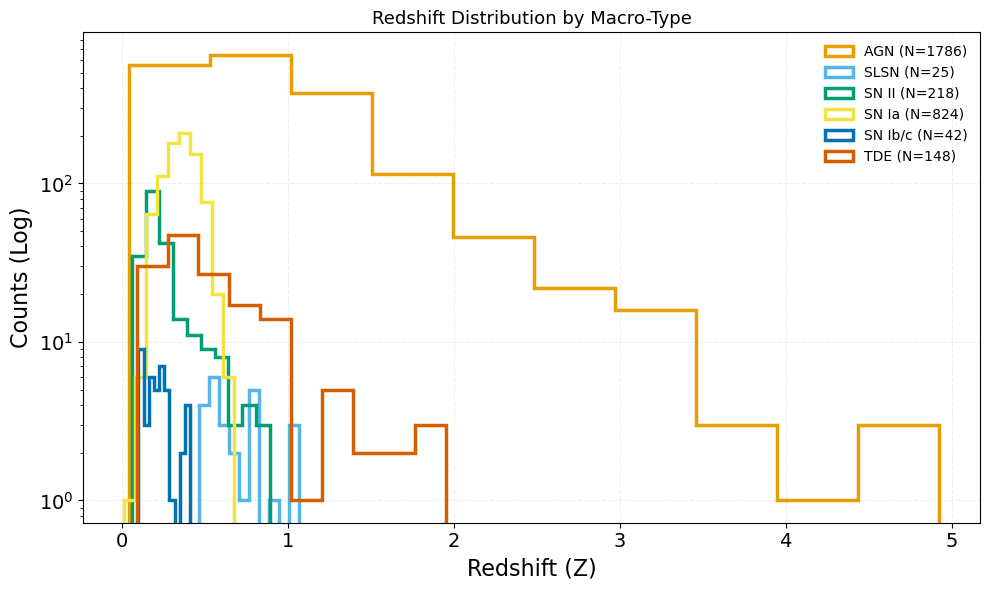

In [18]:
spec_types = train_log['SpecType'].unique()
group_spec = train_log.groupby('SpecType')
def map_spectype(name):
    if 'AGN' in name: return 'AGN'
    if 'TDE' in name: return 'TDE'
    if 'SN Ia' in name: return 'SN Ia'
    if 'SN Ib' in name or 'SN Ic' in name: return 'SN Ib/c'
    if 'SN II' in name: return 'SN II'
    if 'SLSN' in name: return 'SLSN'
    return 'Other'

# Creiamo la nuova colonna nel DataFrame
train_log['MacroType'] = train_log['SpecType'].apply(map_spectype)
group_macro = train_log.groupby('MacroType')


cb_colors = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']

plt.figure(figsize=(10, 6))





for i, (typex, group) in enumerate(train_log.groupby('MacroType')):
    color = cb_colors[i % len(cb_colors)]
    
    plt.hist(group['Z'],  
             histtype='step', 
             label=f'{typex} (N={len(group)})', 
             lw=2.5, 
             color=color)

plt.yscale('log')
plt.xlabel('Redshift (Z)', fontsize=16)
plt.ylabel('Counts (Log)', fontsize=16)
plt.xticks(fontsize = 14)
plt.yticks(fontsize = 14)
plt.title('Redshift Distribution by Macro-Type', fontsize=13)


plt.legend(loc='upper right', frameon=False, fontsize=10)
plt.grid(True, which="major", ls="--", alpha=0.2)

plt.tight_layout()
plt.savefig('Redshift_ditribution.png')
plt.show()

In [19]:
#Splitting train and validation sets
train_df_whole, val_df_whole = train_test_split(
    train_log,
    test_size=0.2,
    random_state=42,
    stratify=train_log['SpecType']
)
df_train_whole = df_train[df_train['object_id'].isin(train_df_whole['object_id'].values)]
spec_type_df = train_df_whole[['object_id', 'SpecType']].drop_duplicates()
df_train_whole = df_train_whole.merge(spec_type_df, on='object_id', how='left') #Adding SpecType column
df_train_whole = df_train_whole.sort_values('Time (MJD)') #Sorting by time
df_train_whole = df_train_whole[df_train_whole['Flux_ext'] >= 0.0] #Removing negative fluxes
df_val_whole = df_train[df_train['object_id'].isin(val_df_whole['object_id'].values)]
spec_type_df_val = val_df_whole[['object_id', 'SpecType']].drop_duplicates()
df_val_whole = df_val_whole.merge(spec_type_df_val, on='object_id', how='left') #Adding SpecType column
df_val_whole = df_val_whole.sort_values('Time (MJD)') #Sorting by time
df_val_whole = df_val_whole[df_val_whole['Flux_ext'] >= 0.0] #Removing negative fluxes


In [20]:
#Undersampling majority classes
classes = train_log['SpecType'].unique()
final_df = []

for c in classes:
    df_c = train_log[train_log['SpecType'] == c]
    if c in ['AGN', 'SN Ia', 'SN II']:
        final_df.append(df_c[:300])
    else:
        final_df.append(df_c)

final_df = pd.concat(final_df)
#Splitting train and validation sets
train_df, val_df = train_test_split(
    final_df,
    test_size=0.2,
    random_state=42,
    stratify=final_df['SpecType']
)

SOM Train dataset

In [21]:

df_train_final = df_train_whole[df_train_whole['object_id'].isin(train_df_whole['object_id'].values)].copy()


classes = df_train_final['SpecType'].unique()
final_df = []

for c in classes:
    df_c = df_train_final[df_train_final['SpecType'] == c]
    
    if c in ['AGN', 'SN Ia', 'SN II']:
        # A. Get the LIST of 300 unique IDs
        target_ids = df_c['object_id'].unique()[:150]
        
        # B. Select ALL rows (all wavelengths/times) for these IDs
        df_subset = df_c[df_c['object_id'].isin(target_ids)]
        final_df.append(df_subset)
    else:
        # Keep rare classes as is
        final_df.append(df_c)

df_train_final = pd.concat(final_df)


# 3. Final Cleaning
df_train_final = df_train_final.sort_values('Time (MJD)')
df_train_final = df_train_final[df_train_final['Flux_ext'] >= 0.0]


print("\n--- FINAL CHECK: Unique Objects per Class ---")
print("(Goal: ~300 for major classes, Original count for TDEs)")

# Group by SpecType and count unique 'object_id'
check_counts = df_train_final.groupby('SpecType')['object_id'].nunique()
print(check_counts)

print(f"\nTotal Rows (Light curve points): {len(df_train_final)}")
print(f"Total Unique Objects: {df_train_final['object_id'].nunique()}")




--- FINAL CHECK: Unique Objects per Class ---
(Goal: ~300 for major classes, Original count for TDEs)
SpecType
AGN                  150
SLSN-I                12
SLSN-II                8
SN II                130
SN IIP                 5
SN IIb                 6
SN IIn                33
SN Ia                150
SN Ia-91T-like        14
SN Ia-91bg-like        3
SN Ia-pec              6
SN Iax[02cx-like]      4
SN Ib                  7
SN Ic                 17
SN Ic-BL              10
TDE                  118
Name: object_id, dtype: int64

Total Rows (Light curve points): 65711
Total Unique Objects: 673


In [22]:
train_log[train_log['SpecType']=='TDE']

,object_id,Z,Z_err,EBV,SpecType,English Translation,split,target,MacroType
12,amon_imloth_luin,0.7766,NaN,0.055,TDE,"hill, steep-sided mount + flowering valley ...",split_01,1,TDE
34,drafn_araf_ryn,0.3243,NaN,0.010,TDE,"hewn, log + wolf + hound of chase",split_01,1,TDE
37,elu_rusc_nath,0.8260,NaN,0.042,TDE,pale blue + fox + web,split_01,1,TDE
69,hervess_hend_lam,0.4506,NaN,0.050,TDE,"wife + eye + tongue, dialect, language",split_01,1,TDE
71,imrad_achas_glamor,0.8000,NaN,0.015,TDE,path + achas + echo,split_01,1,TDE
...,...,...,...,...,...,...,...,...,...
2975,hul_firion_callon,0.0996,NaN,0.163,TDE,cry of encouragement in battle + mortal man...,split_20,1,TDE
2991,lin_graw_hend,0.5886,NaN,0.170,TDE,"lake, pool + bear + eye",split_20,1,TDE
3009,myril_uir_lost,0.6345,NaN,0.126,TDE,"cat + eternity + empty, void",split_20,1,TDE
3010,nath_lang_naer,0.6566,NaN,0.009,TDE,"web + cutlass, sword + sad, dreadful, woeful",split_20,1,TDE


In [23]:
# --- Apply to all three datasets ---
df_features = process_and_flatten(df_train_whole)
df_features_val   = process_and_flatten(df_val_whole)




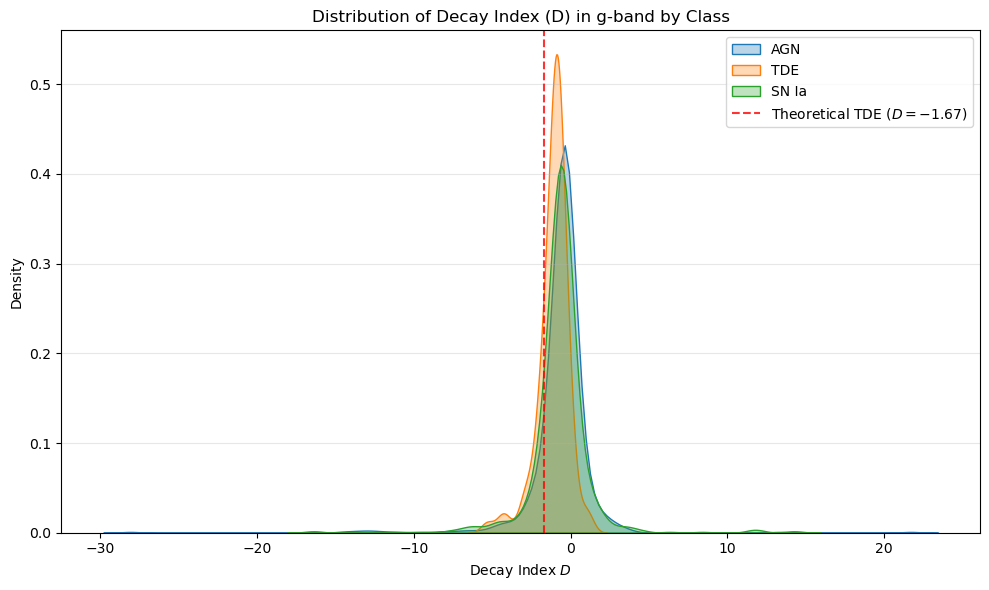

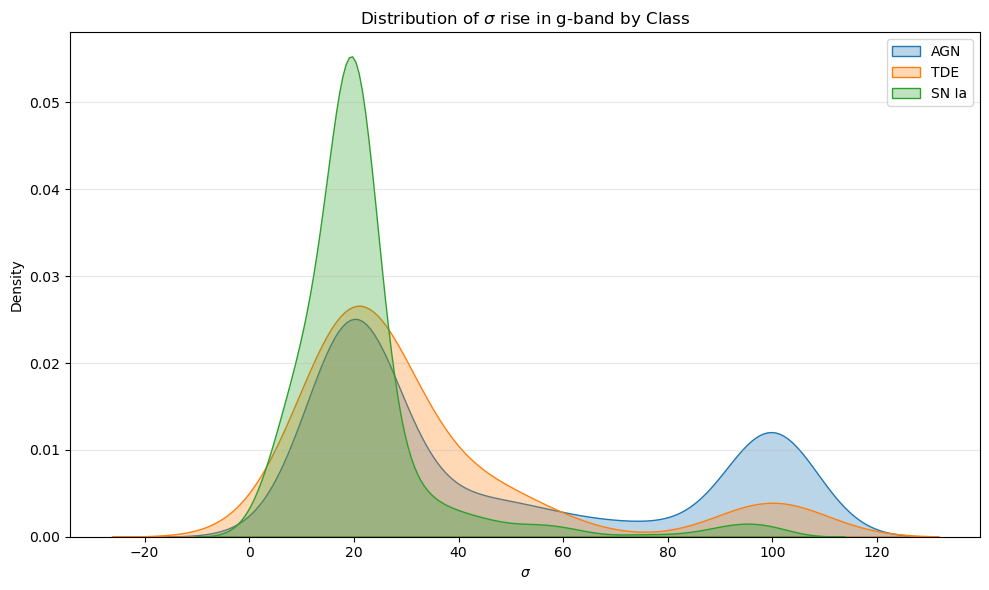

In [44]:

plot_df = df_features.merge(train_log[['object_id', 'SpecType']], on='object_id')


g_band_fits = plot_df[plot_df['decay_D_g'] != 0.0]

# 3. Create the Plot
plt.figure(figsize=(10, 6))

# Plotting each class
for class_name in ['AGN', 'TDE', 'SN Ia', 'Sn II']:
    subset = g_band_fits[g_band_fits['SpecType'] == class_name]
    sns.kdeplot(subset['decay_D_g'], label=class_name, fill=True, alpha=0.3)

# Add a vertical line at the theoretical TDE value (-5/3)
plt.axvline(-1.67, color='red', linestyle='--', alpha=0.8, label='Theoretical TDE ($D = -1.67$)')

plt.title('Distribution of Decay Index (D) in g-band by Class')
plt.xlabel('Decay Index $D$')
plt.ylabel('Density')
#plt.xlim(-5, 2)  # Focus on the most relevant range
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig('decay_D_distribution.png')





g_band_fits = plot_df[plot_df['decay_D_g'] != 0.0]

# 3. Create the Plot
plt.figure(figsize=(10, 6))

# Plotting each class
for class_name in ['AGN', 'TDE', 'SN Ia', 'Sn II']:
    subset = g_band_fits[g_band_fits['SpecType'] == class_name]
    sns.kdeplot(subset['sigma_rise_g'], label=class_name, fill=True, alpha=0.3)



plt.title('Distribution of $\\sigma$ rise in g-band by Class')
plt.xlabel('$\\sigma$')
plt.ylabel('Density')

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig('sigma_distribution.png')




In [27]:
df_features.to_csv('df_features_train.csv', index=True)
df_features_val.to_csv('df_features_val.csv', index=True)

In [28]:
df_features

,object_id,decay_D_g,decay_D_i,decay_D_r,decay_D_u,decay_D_y,decay_D_z,decay_R2_g,decay_R2_i,decay_R2_r,...,max_zscore_r,max_zscore_u,max_zscore_y,max_zscore_z,n_points_g,n_points_i,n_points_r,n_points_u,n_points_y,n_points_z
0,Dornhoth_anwar_melethron,-0.375147,-0.577015,-0.444162,-0.354516,-0.756374,-0.471579,0.462010,0.323937,0.438958,...,2.758852,2.204312,1.750892,2.970953,14.0,29.0,36.0,11.0,15.0,20.0
1,Dornhoth_archam_grond,NaN,0.248329,0.046163,NaN,0.139851,0.062499,NaN,0.795136,0.057026,...,1.597354,1.455333,1.595156,1.775559,4.0,18.0,19.0,5.0,8.0,15.0
2,Dornhoth_certh_iaun,0.167408,-0.958955,-0.916040,0.959851,0.124000,-0.569766,0.024085,0.633050,0.509609,...,3.604184,0.865154,2.163256,2.421402,8.0,21.0,19.0,5.0,11.0,14.0
3,Dornhoth_drafn_celon,1.390115,-0.382137,-1.272246,0.281893,0.324996,-1.003870,0.782775,0.025606,0.592205,...,3.761684,1.584215,2.845905,2.183821,7.0,17.0,17.0,5.0,15.0,11.0
4,Dornhoth_fervain_onodrim,NaN,NaN,-2.257612,NaN,NaN,NaN,NaN,NaN,0.992142,...,1.975388,1.786250,1.734449,NaN,1.0,7.0,7.0,5.0,5.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2429,yll_Mirion_hud,-1.420782,-8.809374,-1.739208,NaN,-1.121273,-0.860008,0.799221,0.221422,0.543449,...,3.243592,1.388689,2.366108,3.365550,10.0,24.0,21.0,6.0,13.0,20.0
2430,yll_gellui_archam,-28.054664,-0.291899,-0.419668,NaN,NaN,0.752749,0.969816,0.212462,0.392355,...,1.574290,1.476426,1.185486,1.481807,7.0,17.0,16.0,6.0,6.0,14.0
2431,yll_lebenedh_cair,-0.339579,-0.815186,-0.897023,-0.130652,-0.836295,-0.641202,0.601944,0.729357,0.661552,...,2.856996,1.854745,2.501592,2.649221,9.0,16.0,25.0,9.0,17.0,29.0
2432,yll_merilin_rach,NaN,-2.999219,-0.833528,NaN,-3.822133,-0.690236,NaN,0.830861,0.932568,...,1.125979,1.142905,1.704578,1.741813,7.0,15.0,14.0,5.0,8.0,17.0


Whole dataset

In [29]:

#Training set t0 and tau computation
t0_per_object = (
    df_train_whole.groupby('object_id').apply(
        lambda obj: obj.loc[obj['Flux'].idxmax(), 'Time (MJD)']
        if obj['Flux_ext'].notna().any() else obj['Time (MJD)'].median()
    )
)

# Map t0 back to df_train_whole
df_train_whole['t0'] = df_train_whole['object_id'].map(t0_per_object)

# Compute tau
df_train_whole['tau'] = df_train_whole['Time (MJD)'] - df_train_whole['t0']

#Validation set t0 and tau computation
t0_per_object = (
    df_val_whole.groupby('object_id').apply(
        lambda obj: obj.loc[obj['Flux'].idxmax(), 'Time (MJD)']
        if obj['Flux_ext'].notna().any() else obj['Time (MJD)'].median()
    )
)
# Map t0 back to df_val_whole
df_val_whole['t0'] = df_val_whole['object_id'].map(t0_per_object)
# Compute tau
df_val_whole['tau'] = df_val_whole['Time (MJD)'] - df_val_whole['t0']

Training subsampled dataset

In [30]:

t0_per_object = (
    df_train_final.groupby('object_id').apply(
        lambda obj: obj.loc[obj['Flux'].idxmax(), 'Time (MJD)']
        if obj['Flux_ext'].notna().any() else obj['Time (MJD)'].median()
    )
)

# Map t0 back to df_train_final
df_train_final['t0'] = df_train_final['object_id'].map(t0_per_object)

# Compute tau
df_train_final['tau'] = df_train_final['Time (MJD)'] - df_train_final['t0']

Filtering datasets

In [31]:
df_train_filtered = noise_removal(df_train_final) #FIltered train dataset
df_train_noise_removed = noise_removal(df_train_whole) # All light curves
df_val_noise_removed = noise_removal(df_val_whole) # All light curves

Normalization 

In [32]:
#Filtered train dataset
# Baseline, F_hat, Amplitude, F_norm, phi
F_base = df_train_filtered[df_train_filtered['tau']<0].groupby('object_id')['Flux_ext'].median()
df_train_filtered['F_base'] = df_train_filtered['object_id'].map(F_base)
df_train_filtered['F_hat'] = df_train_filtered['Flux_ext'] - df_train_filtered['F_base']
Amplitude = df_train_filtered.groupby('object_id')['F_hat'].max()
df_train_filtered['Amplitude'] = df_train_filtered['object_id'].map(Amplitude)
df_train_filtered = df_train_filtered[df_train_filtered['Amplitude']>0]
df_train_filtered['F_norm'] = df_train_filtered['F_hat']/df_train_filtered['Amplitude']
df_train_filtered['phi'] = df_train_filtered.groupby('object_id')['tau'].transform(
    lambda x: (x-x.min())/(x.max()-x.min()) if x.max()!=x.min() else 0.0
)
df_train_filtered['F_norm_err'] = df_train_filtered['Flux_err'] / df_train_filtered['Amplitude']


# All classess train
F_base = df_train_noise_removed[df_train_noise_removed['tau']<0].groupby('object_id')['Flux_ext'].median()
df_train_noise_removed['F_base'] = df_train_noise_removed['object_id'].map(F_base)
df_train_noise_removed['F_hat'] = df_train_noise_removed['Flux_ext'] - df_train_noise_removed['F_base']
Amplitude = df_train_noise_removed.groupby('object_id')['F_hat'].max()
df_train_noise_removed['Amplitude'] = df_train_noise_removed['object_id'].map(Amplitude)
df_train_noise_removed = df_train_noise_removed[df_train_noise_removed['Amplitude']>0]
df_train_noise_removed['F_norm'] = df_train_noise_removed['F_hat']/df_train_noise_removed['Amplitude']
df_train_noise_removed['phi'] = df_train_noise_removed.groupby('object_id')['tau'].transform(
    lambda x: (x-x.min())/(x.max()-x.min()) if x.max()!=x.min() else 0.0)
df_train_noise_removed['F_norm_err'] = df_train_noise_removed['Flux_err'] / df_train_noise_removed['Amplitude']

# All classess validation
F_base = df_val_noise_removed[df_val_noise_removed['tau']<0].groupby('object_id')['Flux_ext'].median()
df_val_noise_removed['F_base'] = df_val_noise_removed['object_id'].map(F_base)
df_val_noise_removed['F_hat'] = df_val_noise_removed['Flux_ext'] - df_val_noise_removed['F_base']
Amplitude = df_val_noise_removed.groupby('object_id')['F_hat'].max()
df_val_noise_removed['Amplitude'] = df_val_noise_removed['object_id'].map(Amplitude)
df_val_noise_removed = df_val_noise_removed[df_val_noise_removed['Amplitude']>0]
df_val_noise_removed['F_norm'] = df_val_noise_removed['F_hat']/df_val_noise_removed['Amplitude']
df_val_noise_removed['phi'] = df_val_noise_removed.groupby('object_id')['tau'].transform(
    lambda x: (x-x.min())/(x.max()-x.min()) if x.max()!=x.min() else 0.0)
df_val_noise_removed['F_norm_err'] = df_val_noise_removed['Flux_err'] / df_val_noise_removed['Amplitude']    


In [33]:
os.makedirs('curves_plot', exist_ok=True)

# initial filter for the object
#tde = df_train[df_train['object_id'] == 'amon_imloth_luin']
bands = df_train['Filter'].unique()

plt.figure(figsize=(10, 6)) # Optional: Make the plot bigger
for object_id  in df_train['object_id'].unique():
    # Filter for the specific object
    object_data = df_train[df_train['object_id'] == object_id]
    spec_type = train_log[train_log['object_id'] == object_id]['SpecType'].iloc[0]
    for band in bands:

        # 1. Filter for the specific band
        band_data = object_data[object_data['Filter'] == band]
        
        # 2. Sort ONLY this band's data by time
        band_data = band_data.sort_values(by='Time (MJD)')
    
    # 3. Plot
        plt.plot(band_data['Time (MJD)'], band_data['Flux_ext'], label=band, marker='o')

    plt.xlabel('Time (MJD)')
    plt.ylabel('Flux')
    plt.title(f'Light Curve for {object_id}: SpecType: {spec_type}')
    plt.legend()
    plt.savefig(f'curves_plot/{object_id}_lightcurve.png')
    plt.close()

Visualizzazione dei grafici TDE trovati in 'curves_plot':

Oggetto: amon_imloth_luin (SpecType: TDE)


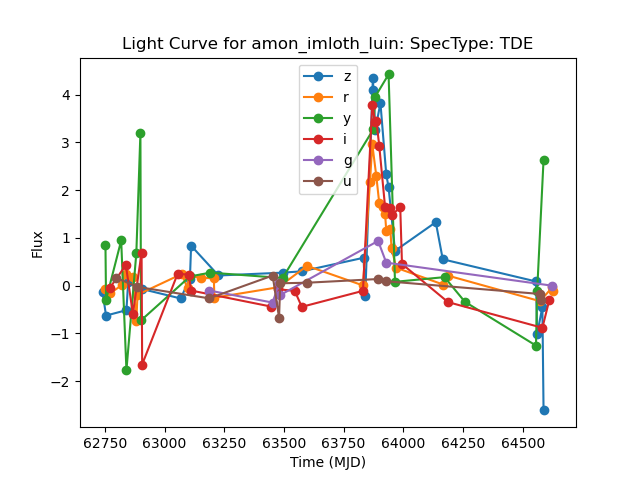

Oggetto: drafn_araf_ryn (SpecType: TDE)


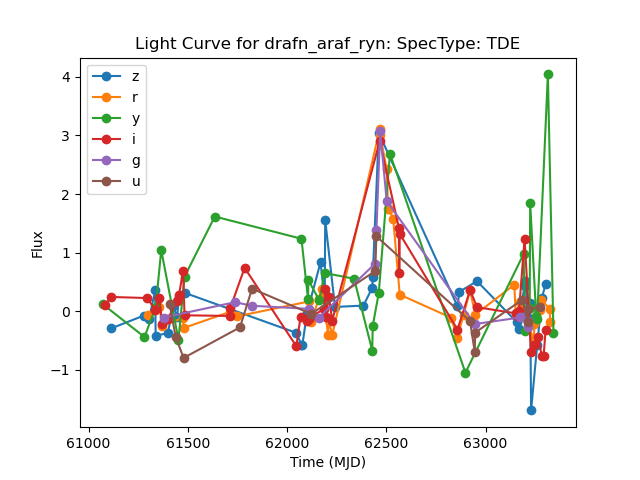

Oggetto: elu_rusc_nath (SpecType: TDE)


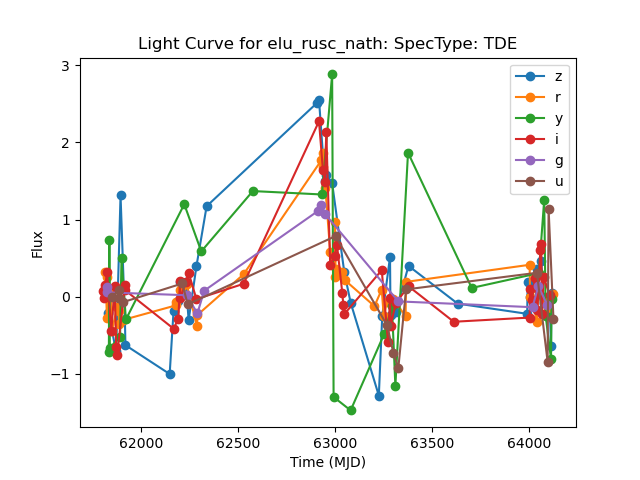

Oggetto: hervess_hend_lam (SpecType: TDE)


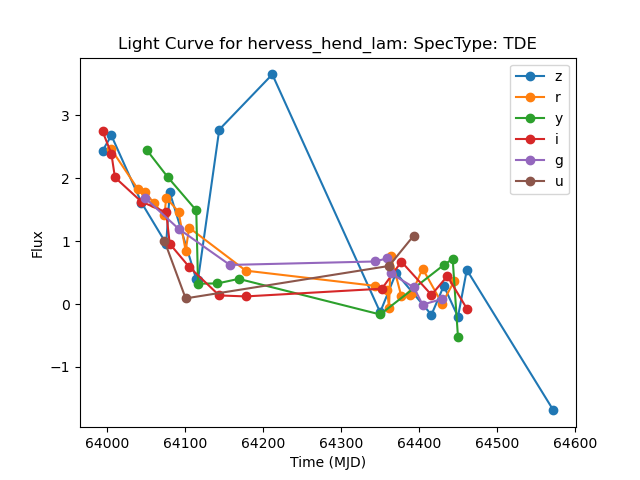

Oggetto: imrad_achas_glamor (SpecType: TDE)


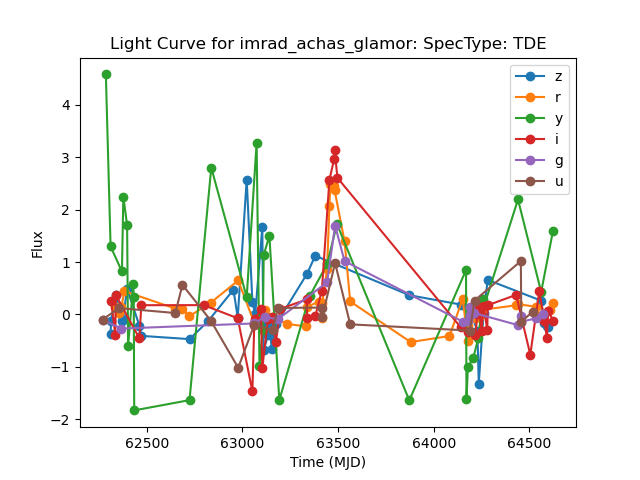

Oggetto: mithril_suil_cugu (SpecType: TDE)


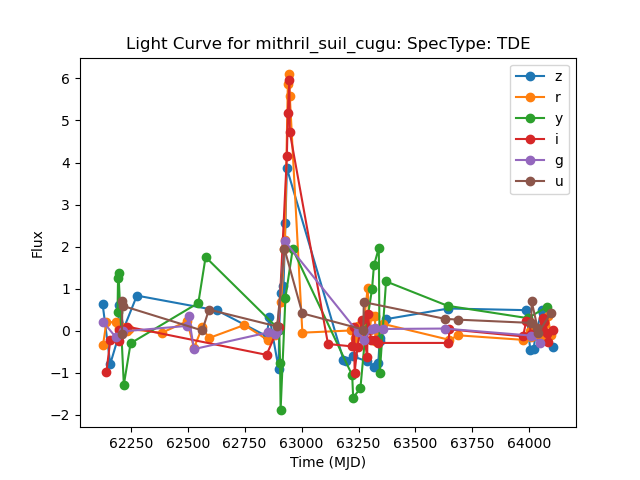

Oggetto: pent_agor_bronwe (SpecType: TDE)


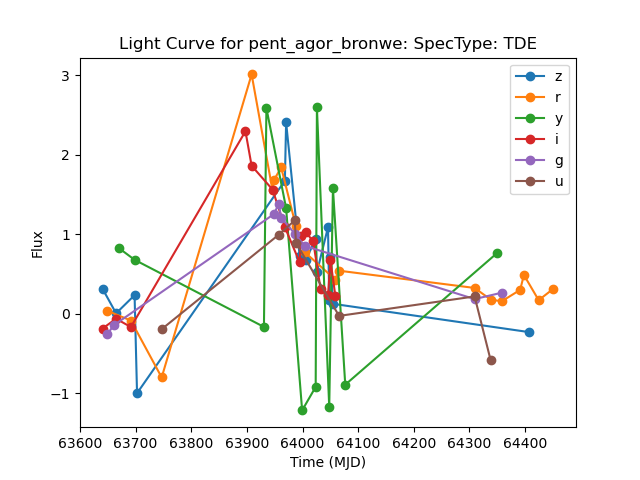

Oggetto: raef_hud_baug (SpecType: TDE)


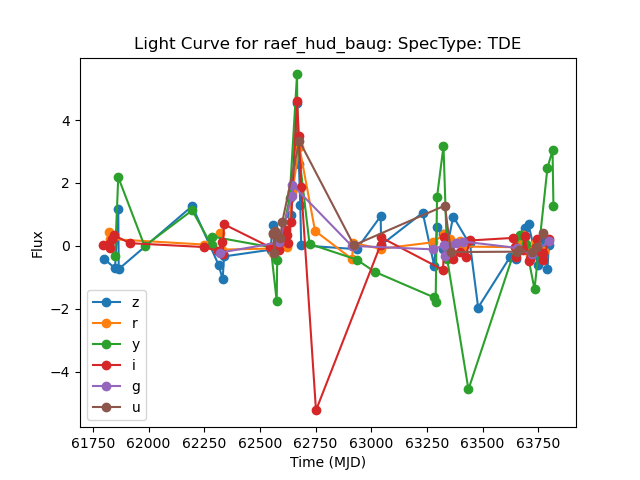

Oggetto: ram_thavron_rusc (SpecType: TDE)


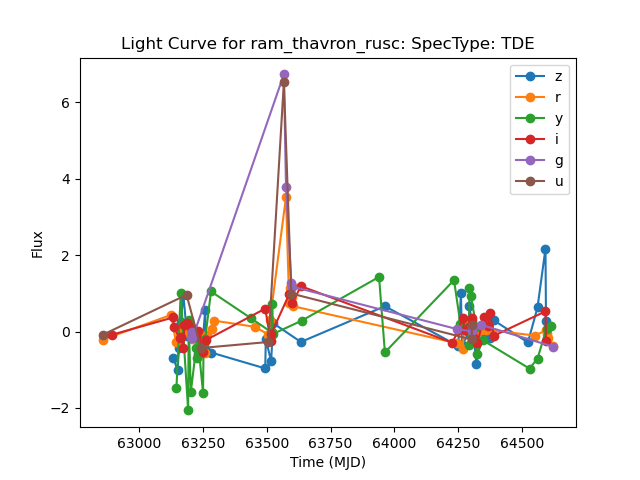

Oggetto: suil_sogannen_bain (SpecType: TDE)


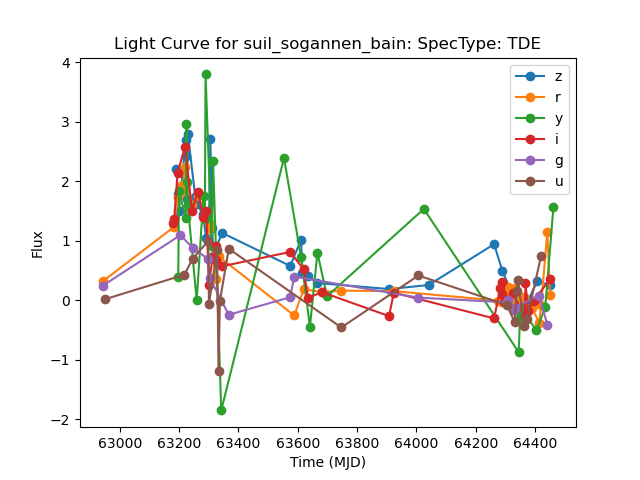

Oggetto: thamas_hud_cuil (SpecType: TDE)


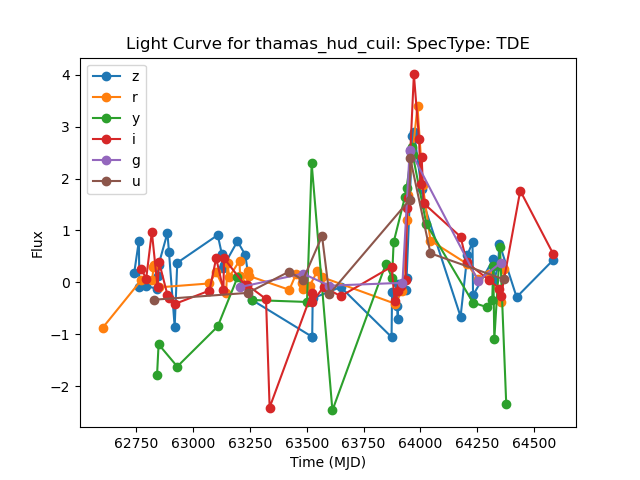

Oggetto: tobas_Elrim_salph (SpecType: TDE)


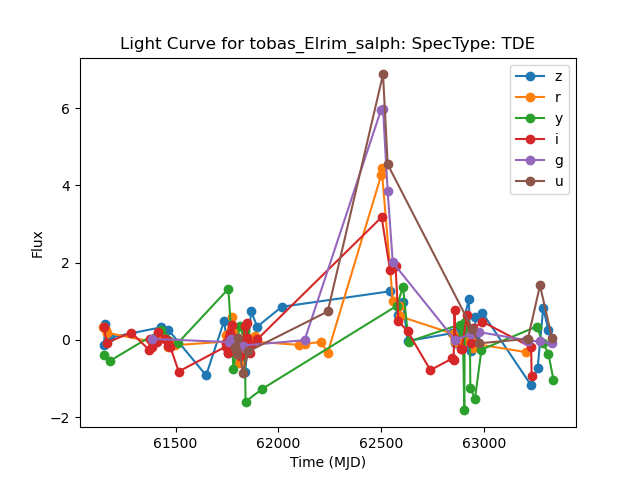

Oggetto: Druadan_rodwen_bragol (SpecType: TDE)


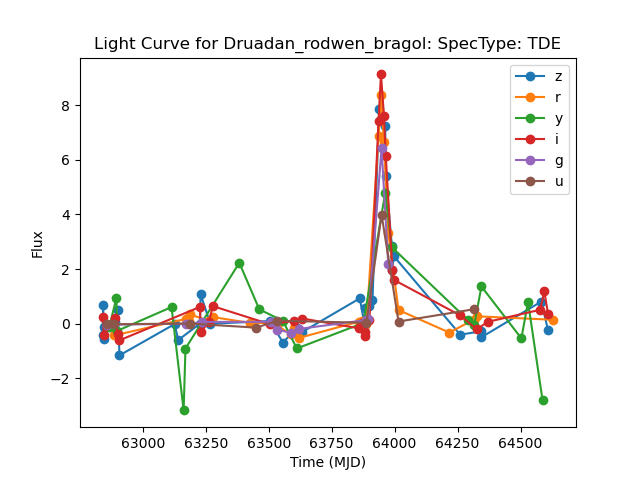

Oggetto: Elrim_harad_menel (SpecType: TDE)


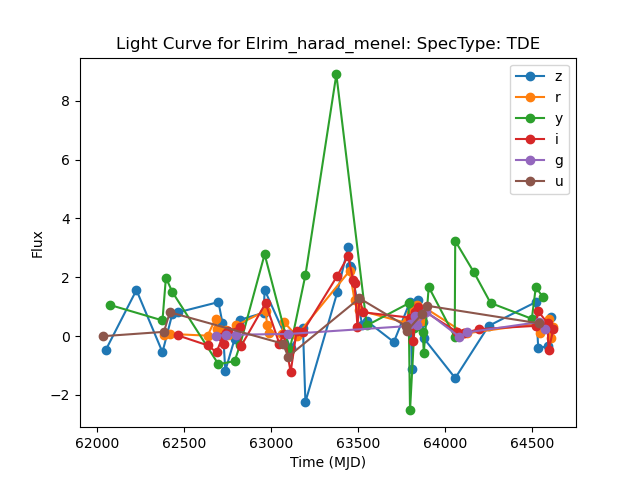

Oggetto: angos_rochir_aras (SpecType: TDE)


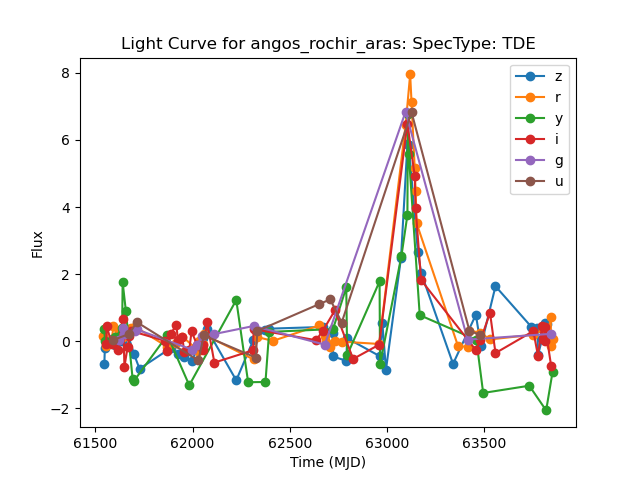

Oggetto: gaurwaith_tamin_ungol (SpecType: TDE)


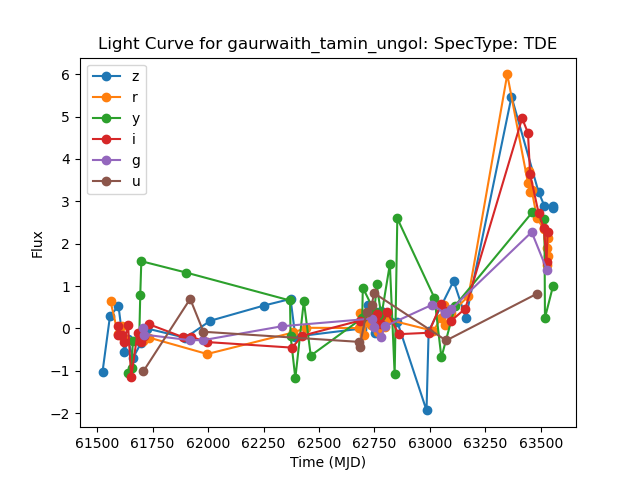

Oggetto: gwarth_bellas_glamor (SpecType: TDE)


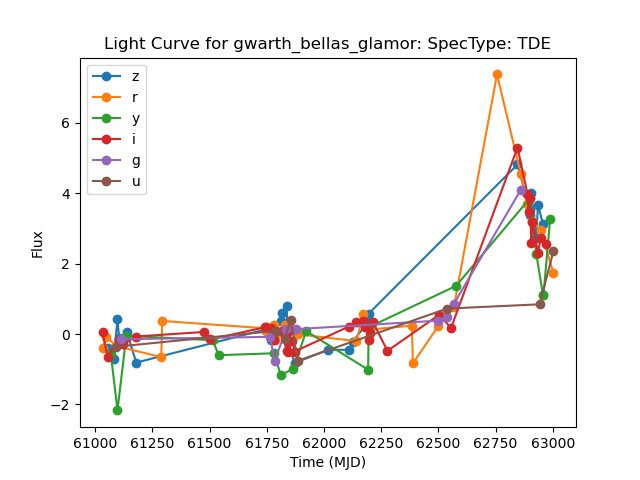

Oggetto: harad_tirith_mithren (SpecType: TDE)


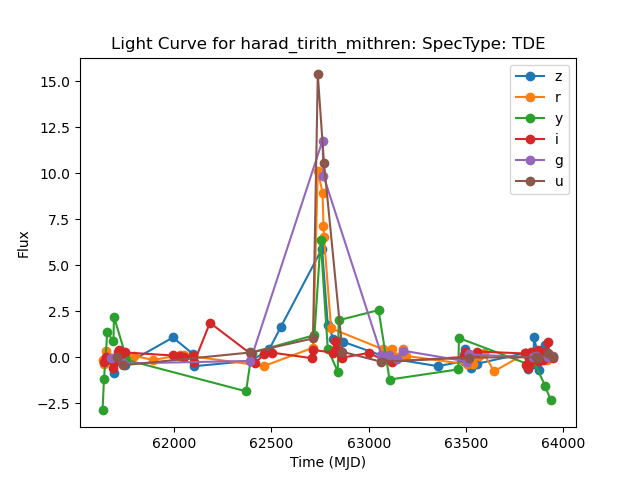

Oggetto: helegnen_faradrim_cae (SpecType: TDE)


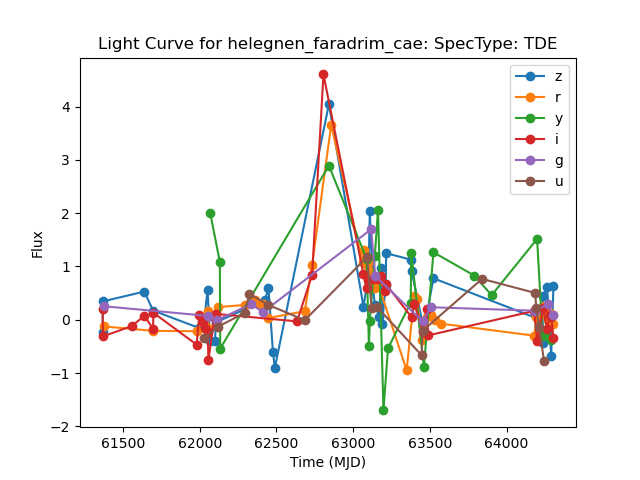

Oggetto: hud_bregedur_rist (SpecType: TDE)


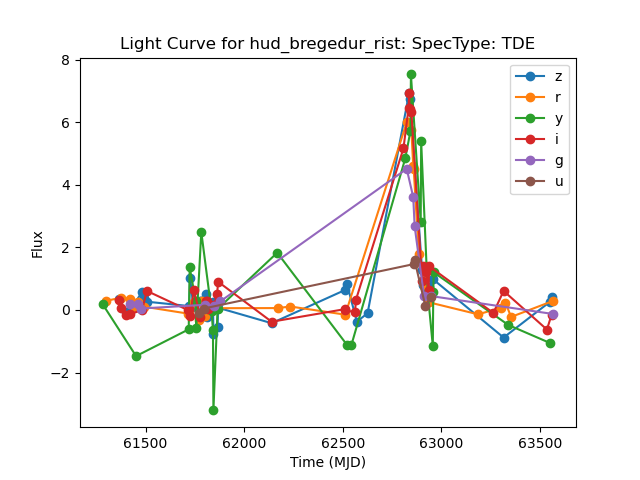

Oggetto: melethron_graw_imrath (SpecType: TDE)


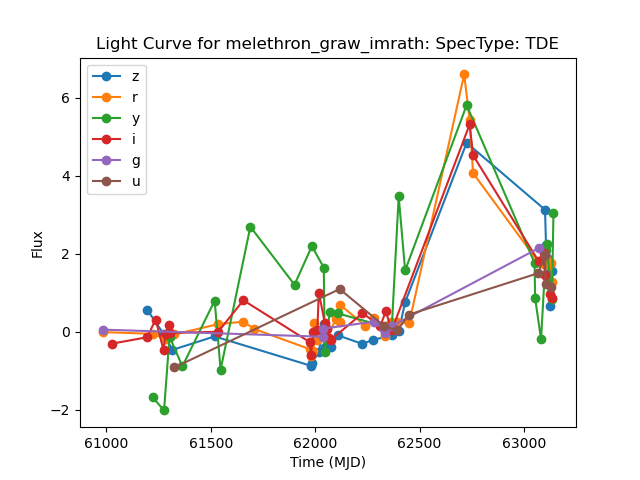

Oggetto: rhun_anwar_iaun (SpecType: TDE)


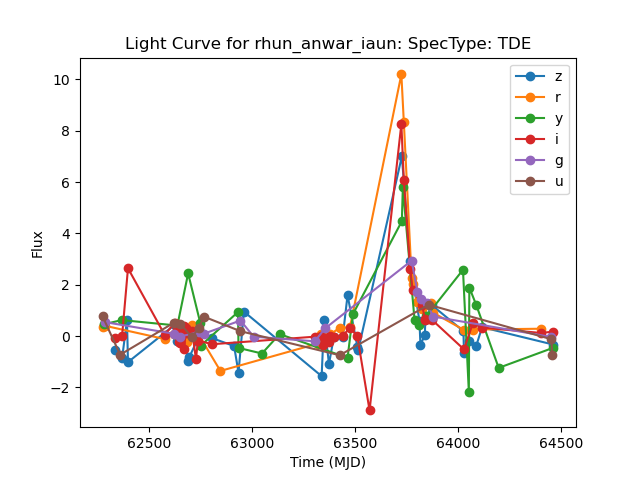

Oggetto: rusc_erchion_balrog (SpecType: TDE)


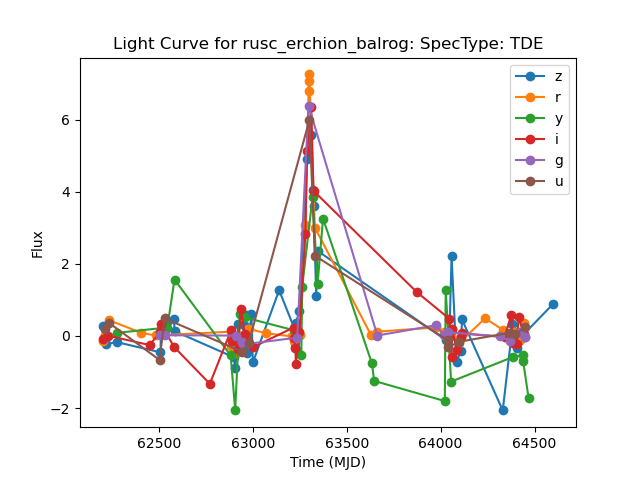

Oggetto: saelor_glass_cenedril (SpecType: TDE)


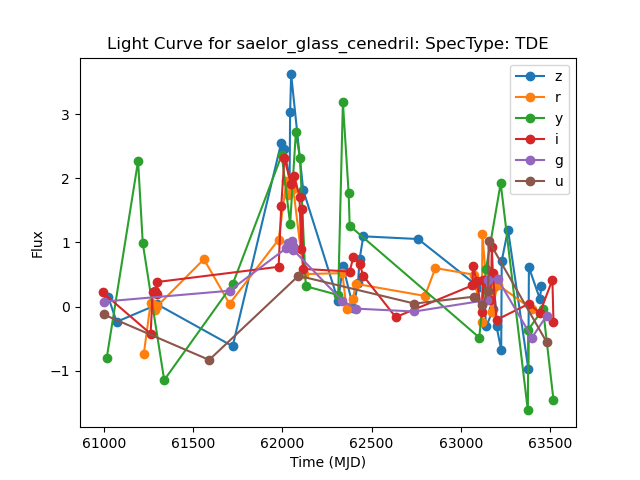

Oggetto: Eru_saelor_tegilbor (SpecType: TDE)


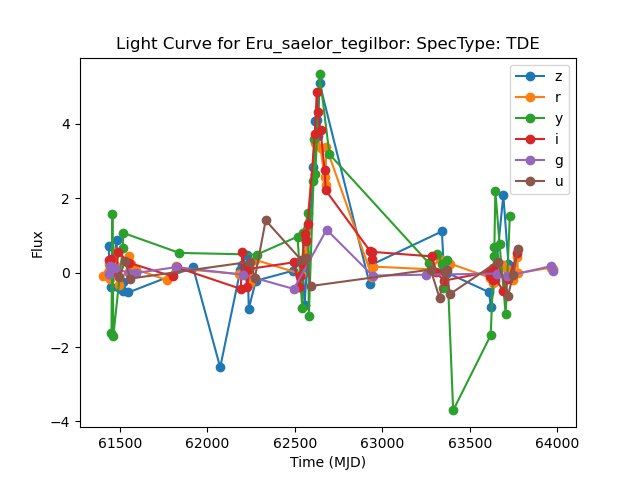

Oggetto: erchion_lobor_hwiniol (SpecType: TDE)


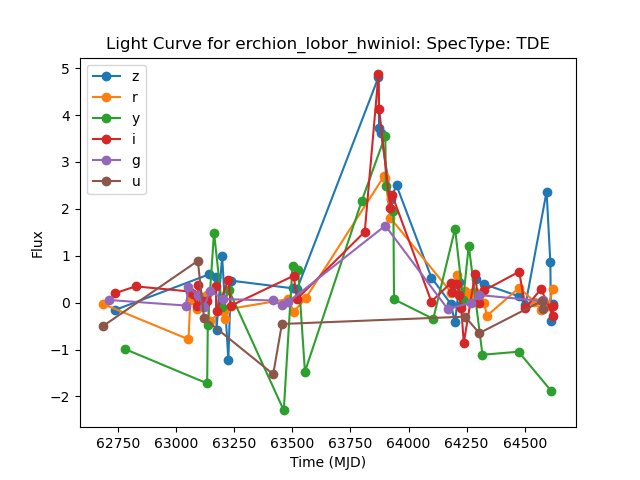

Oggetto: gwathui_navaer_glaur (SpecType: TDE)


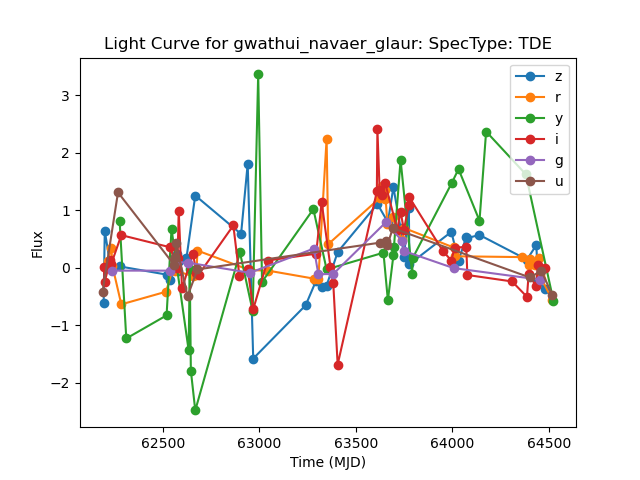

Oggetto: Gwathuirim_meldir_fuin (SpecType: TDE)


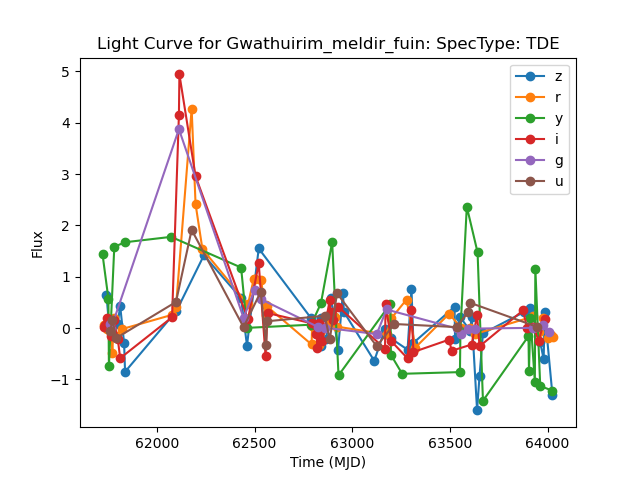

Oggetto: Sindarin_araf_pilin (SpecType: TDE)


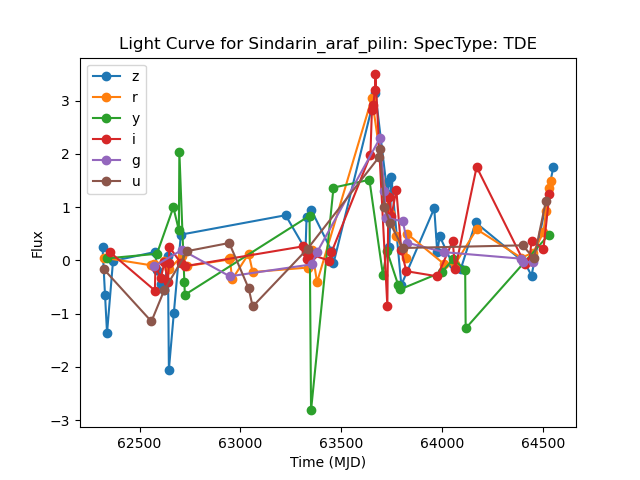

Oggetto: amon_cirion_annon (SpecType: TDE)


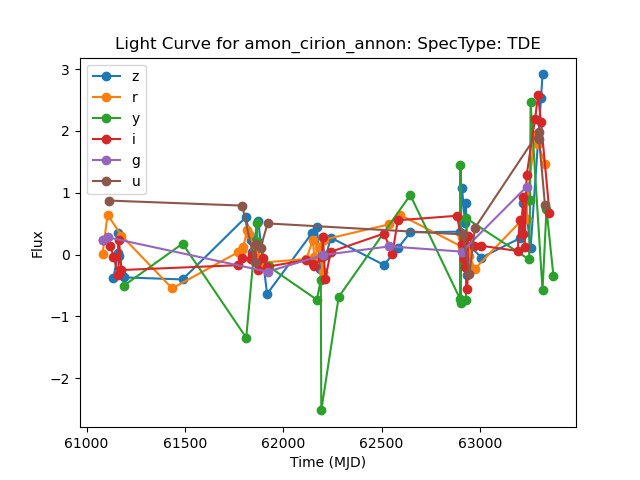

Oggetto: anwar_gilgalad_luith (SpecType: TDE)


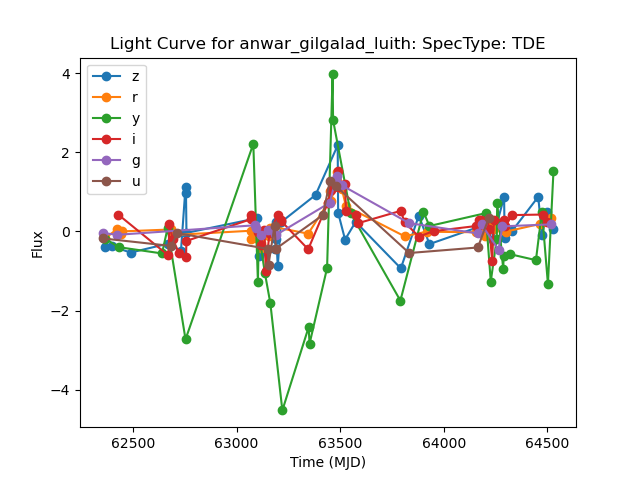

Oggetto: eirien_Druadan_ingem (SpecType: TDE)


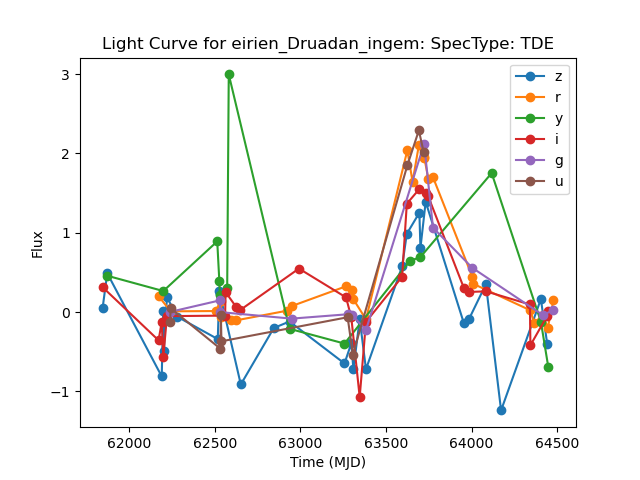

Oggetto: fang_thamas_eirien (SpecType: TDE)


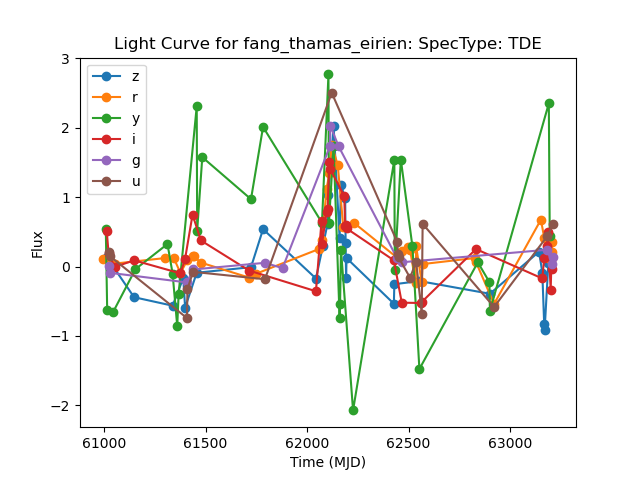

Oggetto: fuin_ryn_amdir (SpecType: TDE)


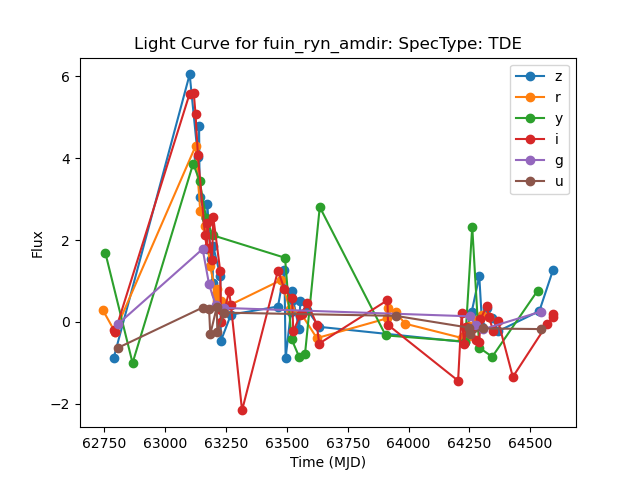

Oggetto: ithron_galvorn_gaur (SpecType: TDE)


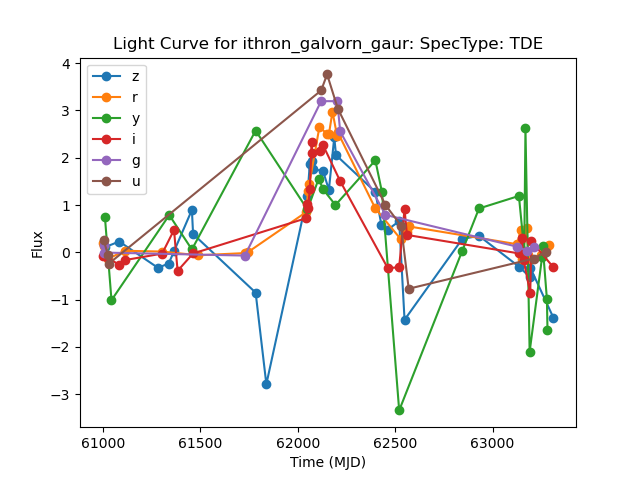

Oggetto: raef_Mirion_lebed (SpecType: TDE)


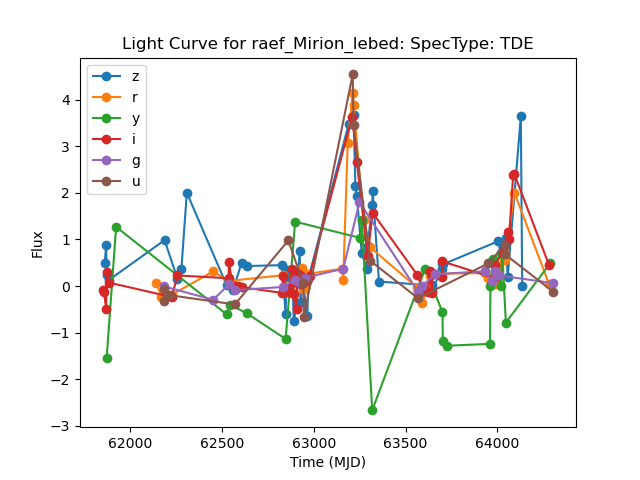

Oggetto: salab_tirith_Ithil (SpecType: TDE)


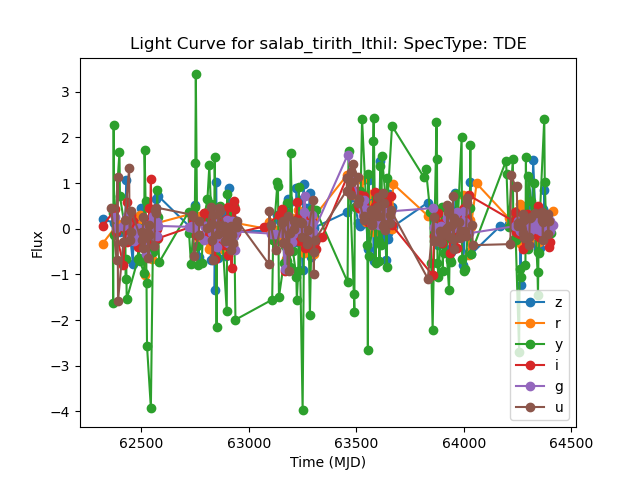

Oggetto: thurin_aegas_bregedur (SpecType: TDE)


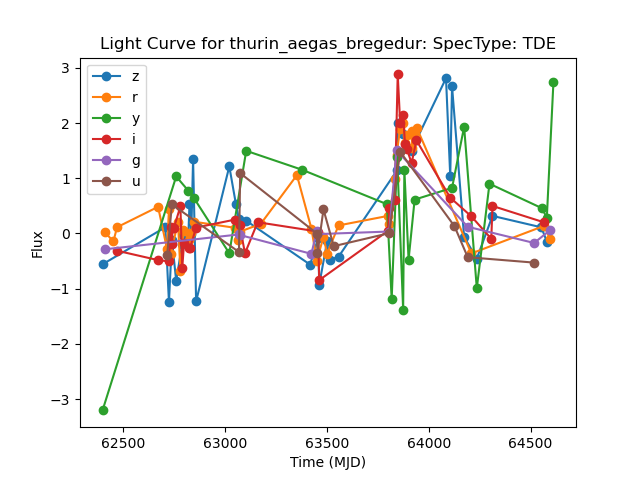

Oggetto: tobas_hun_peredhel (SpecType: TDE)


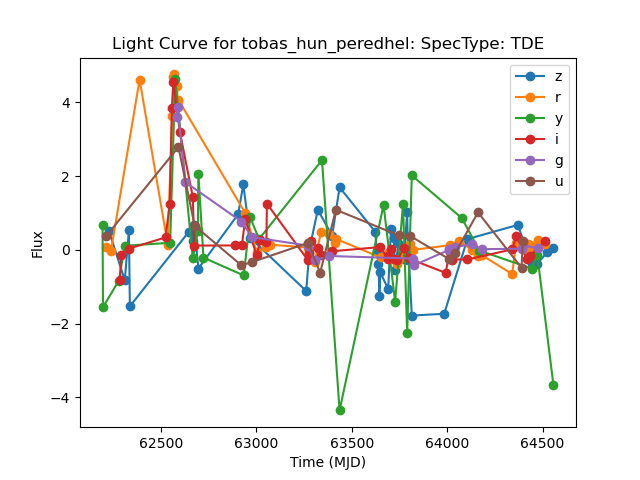

Oggetto: achas_saer_hand (SpecType: TDE)


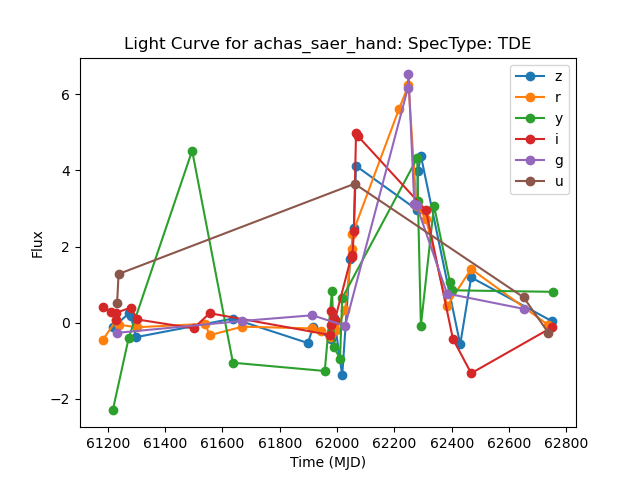

Oggetto: hun_maen_hervess (SpecType: TDE)


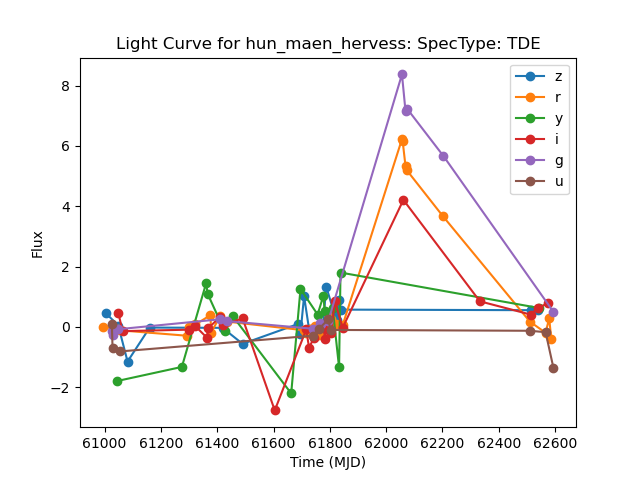

Oggetto: hwiniol_randir_nell (SpecType: TDE)


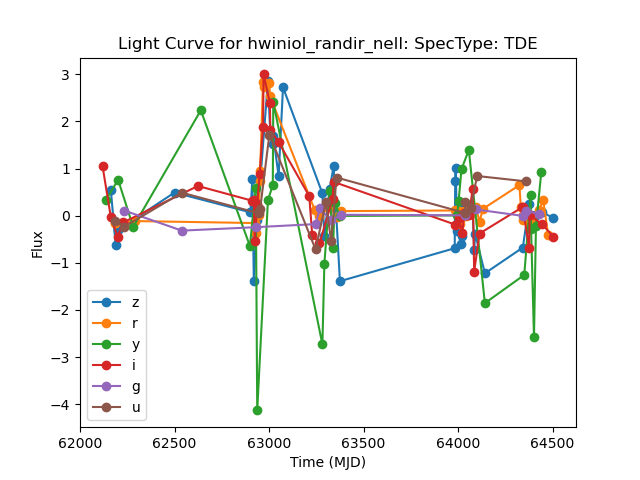

Oggetto: maethor_tann_daen (SpecType: TDE)


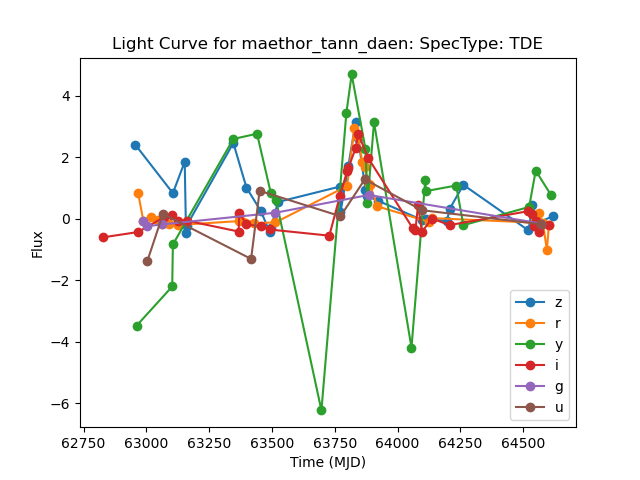

Oggetto: pendrath_alph_luin (SpecType: TDE)


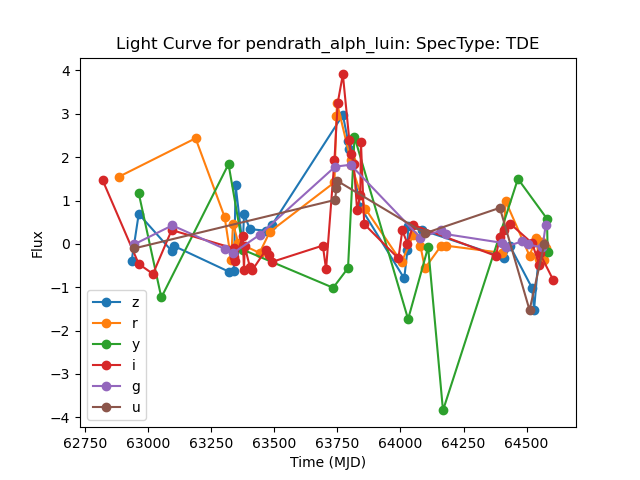

Oggetto: pennas_lunt_tinnu (SpecType: TDE)


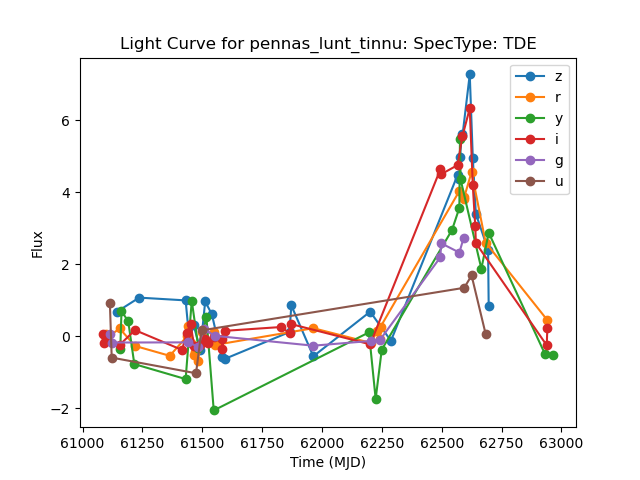

Oggetto: Mithrim_alae_cund (SpecType: TDE)


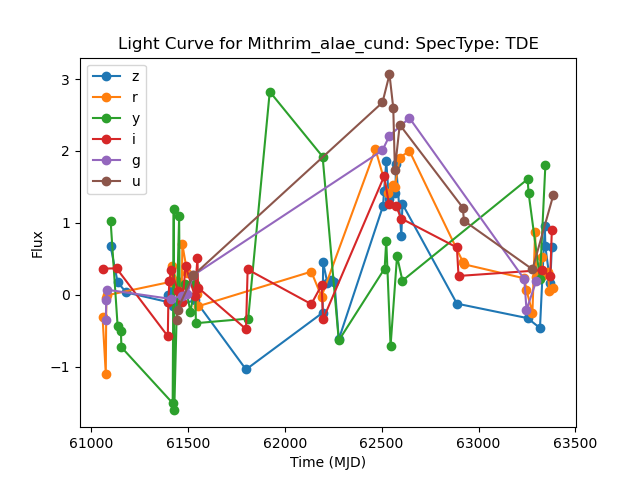

Oggetto: aran_saew_rodwen (SpecType: TDE)


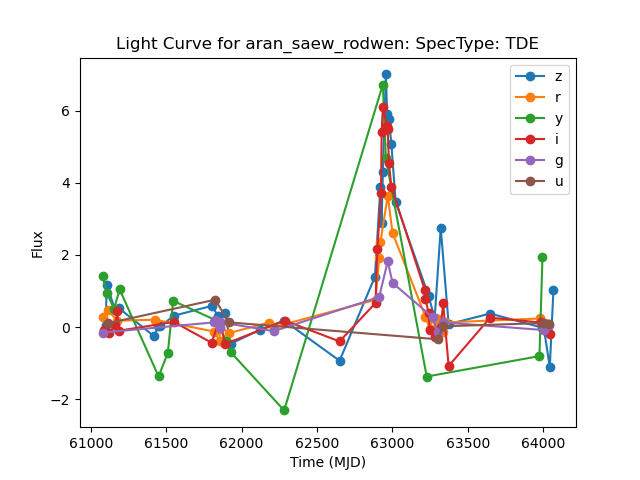

Oggetto: bregedur_rom_rochben (SpecType: TDE)


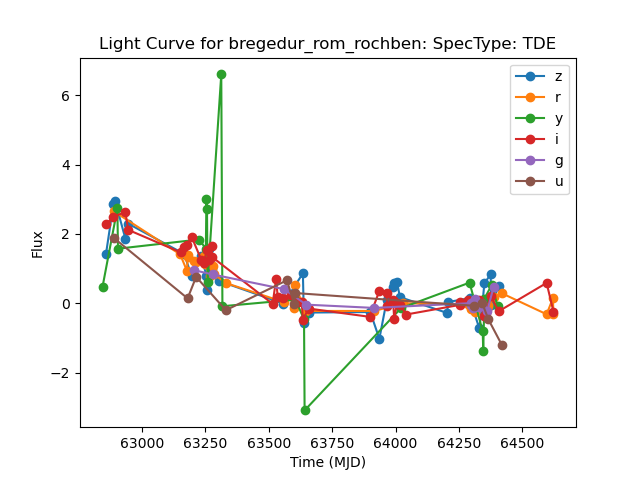

Oggetto: gondrath_luithien_cugu (SpecType: TDE)


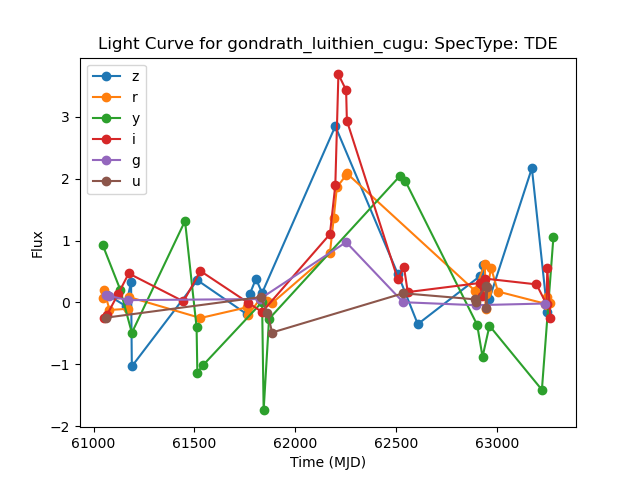

Oggetto: malad_cabor_Sindarin (SpecType: TDE)


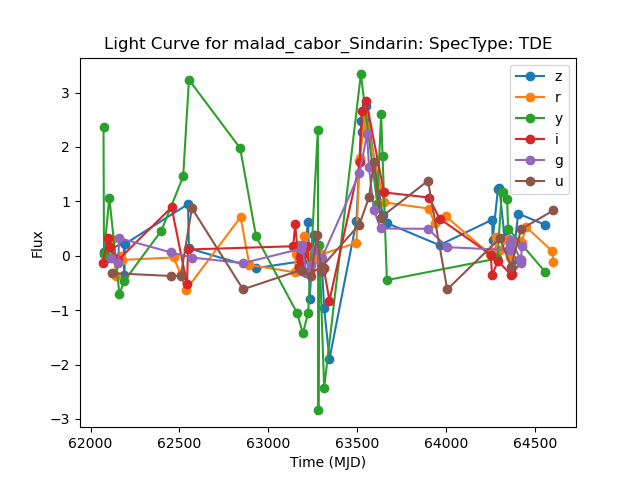

Oggetto: mir_aglareb_Eluwaith (SpecType: TDE)


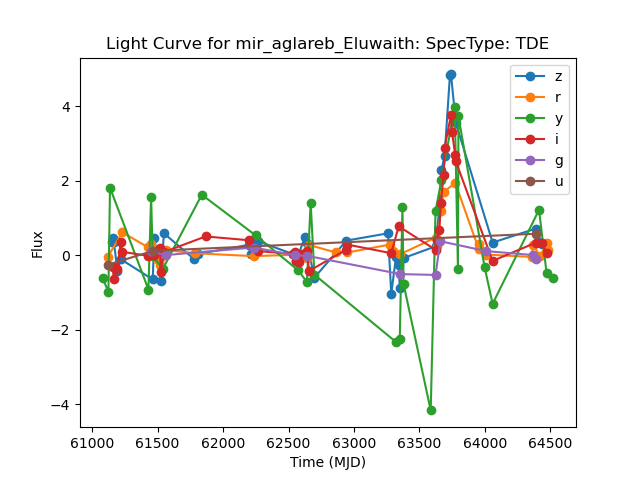

Oggetto: nell_tinuviel_adel (SpecType: TDE)


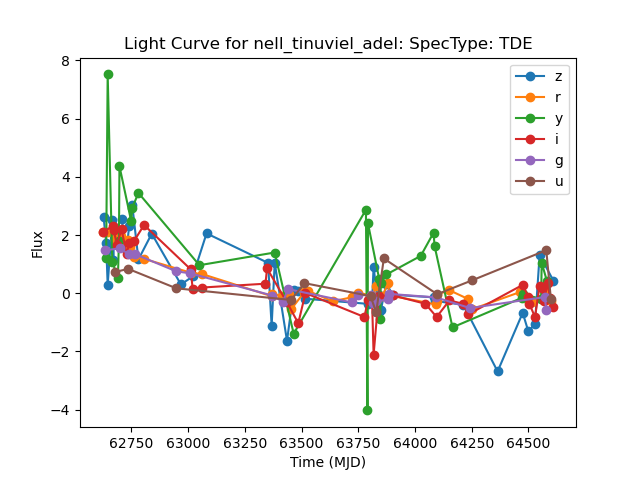

Oggetto: thangail_galadh_rodwen (SpecType: TDE)


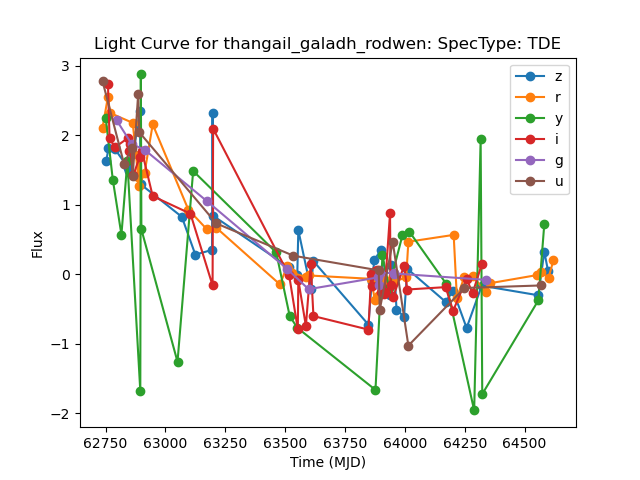

Oggetto: ylf_meldir_amloth (SpecType: TDE)


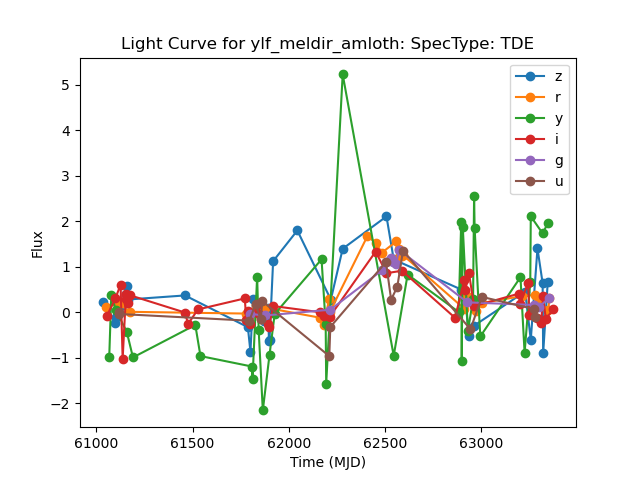

Oggetto: baneth_thurin_meldir (SpecType: TDE)


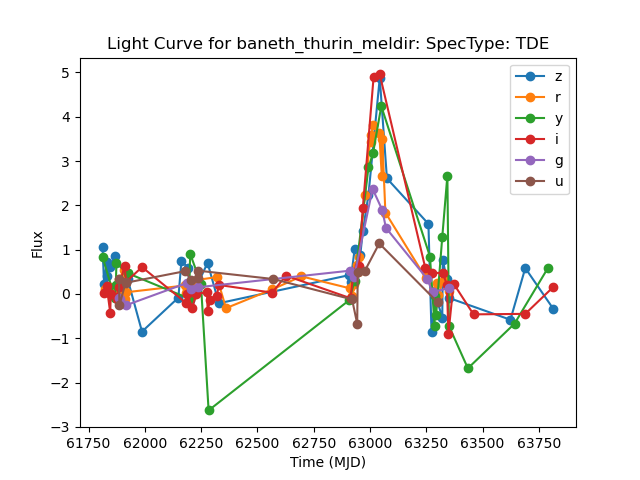

Oggetto: gath_talraph_iaun (SpecType: TDE)


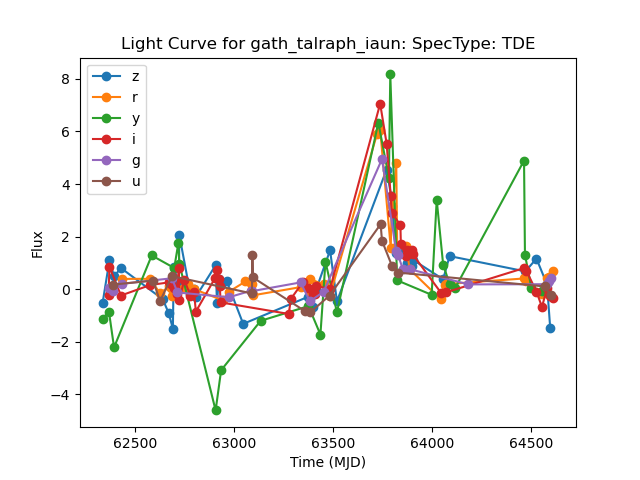

Oggetto: lin_gwaloth_hu (SpecType: TDE)


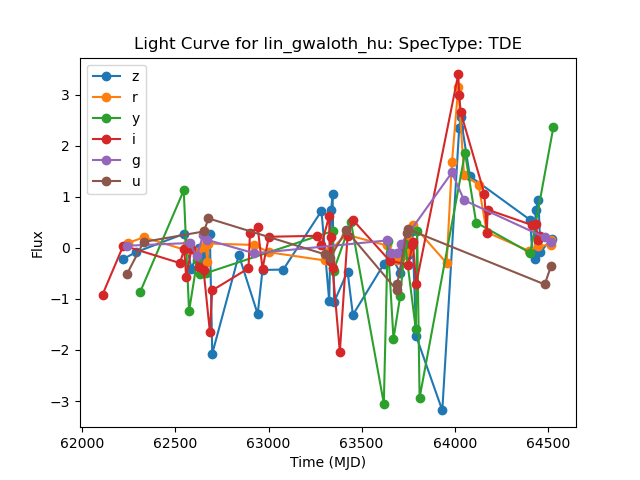

Oggetto: rhosc_galadhrim_rhovan (SpecType: TDE)


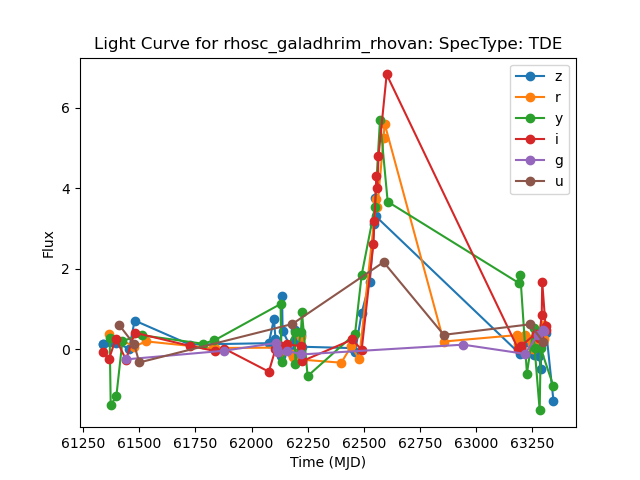

Oggetto: rom_maecheneb_lacha (SpecType: TDE)


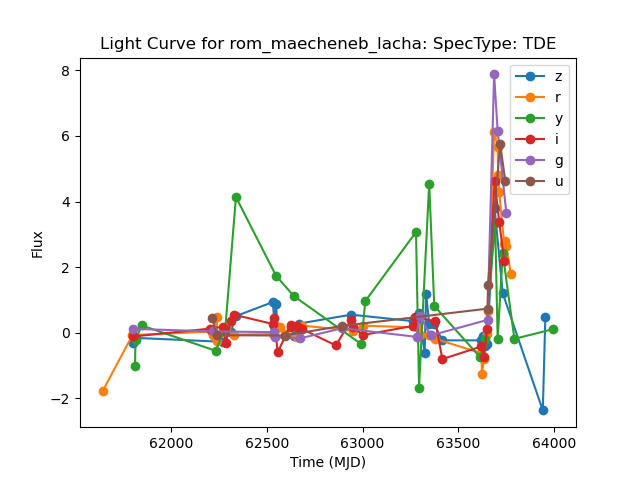

Oggetto: tachol_anwar_mindon (SpecType: TDE)


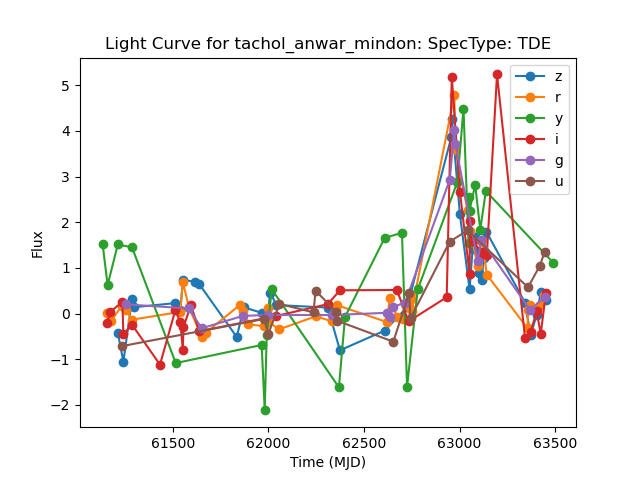

Oggetto: hud_eryn_ylf (SpecType: TDE)


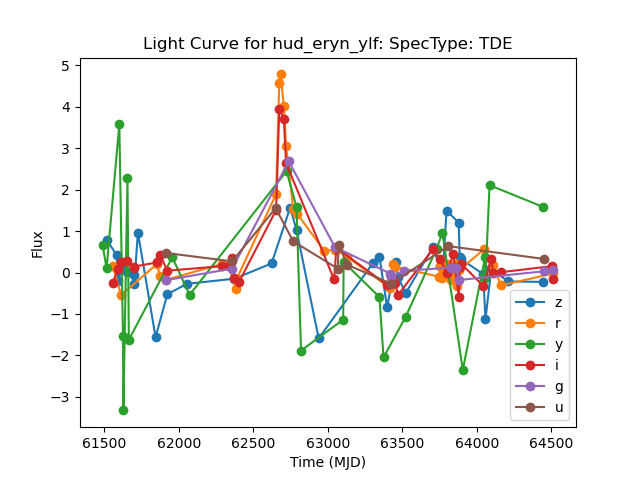

Oggetto: melethron_Rochirrim_Mithrim (SpecType: TDE)


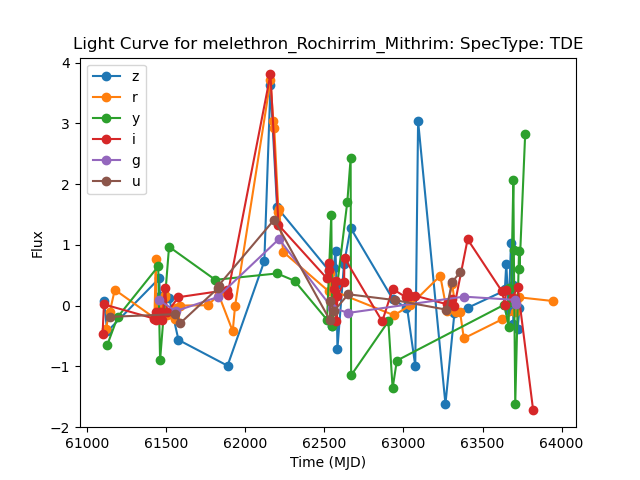

Oggetto: pilin_lebenedh_cund (SpecType: TDE)


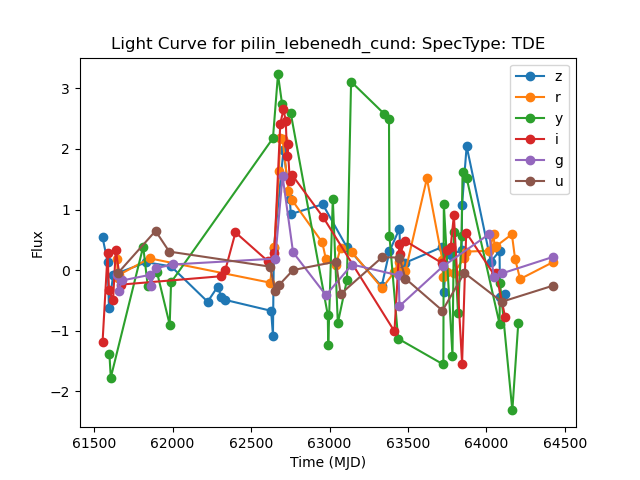

Oggetto: ank_anann_cugu (SpecType: TDE)


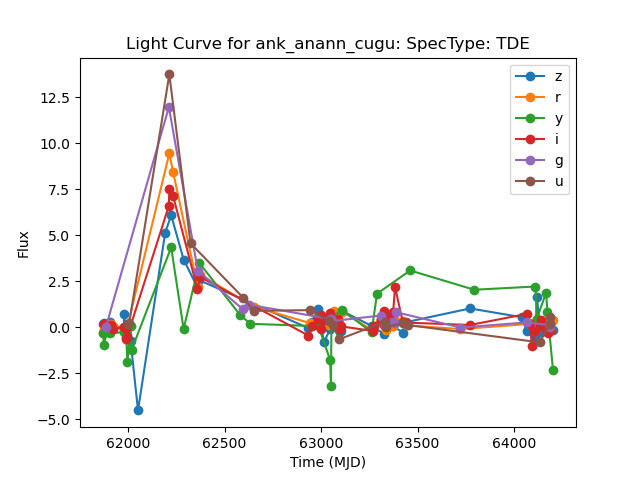

Oggetto: ninglor_rhovan_midh (SpecType: TDE)


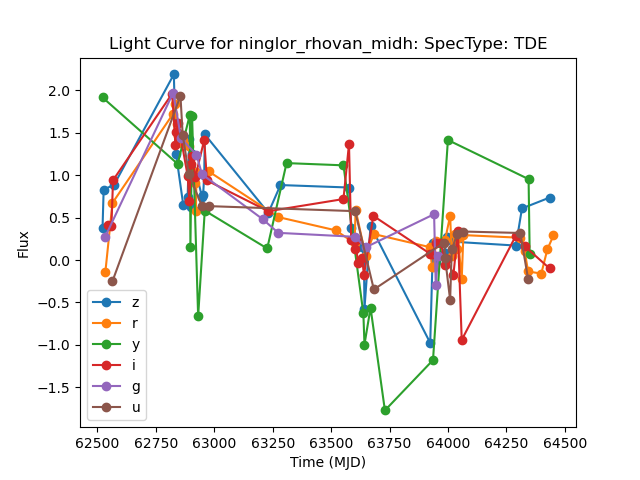

Oggetto: suil_gellui_nim (SpecType: TDE)


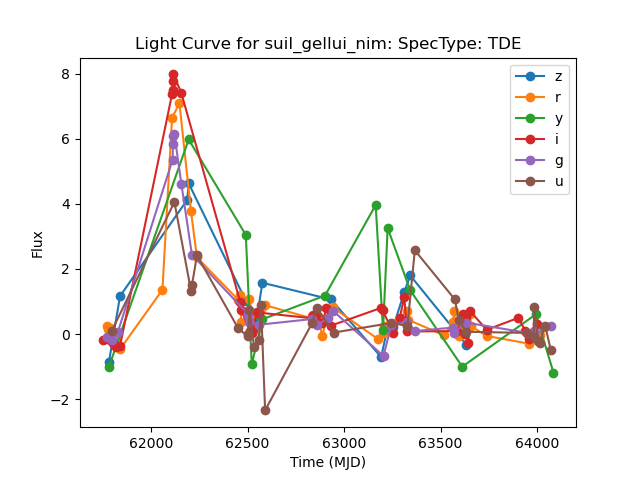

Oggetto: alag_haradrim_celair (SpecType: TDE)


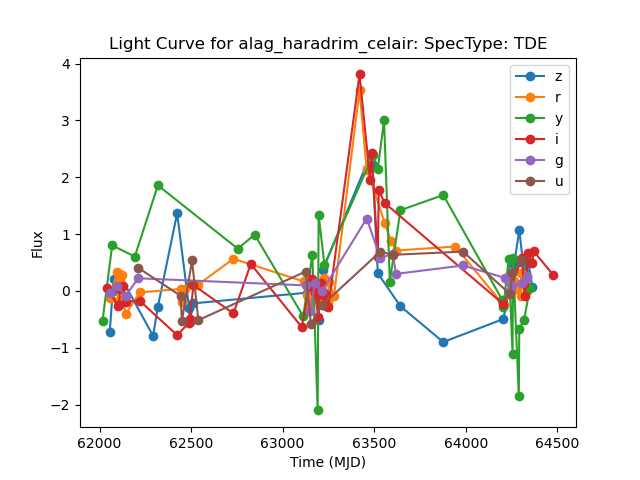

Oggetto: hand_cund_hul (SpecType: TDE)


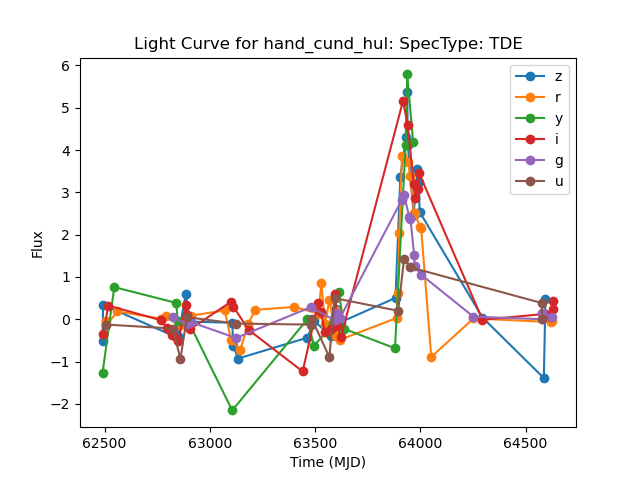

Oggetto: heleg_amarth_soga (SpecType: TDE)


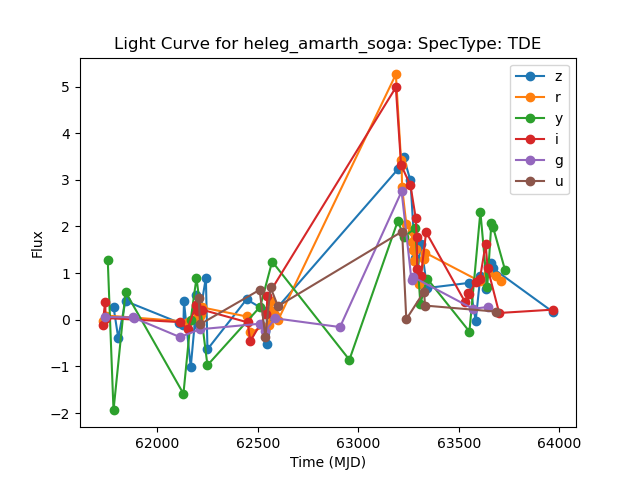

Oggetto: rochben_ylf_grond (SpecType: TDE)


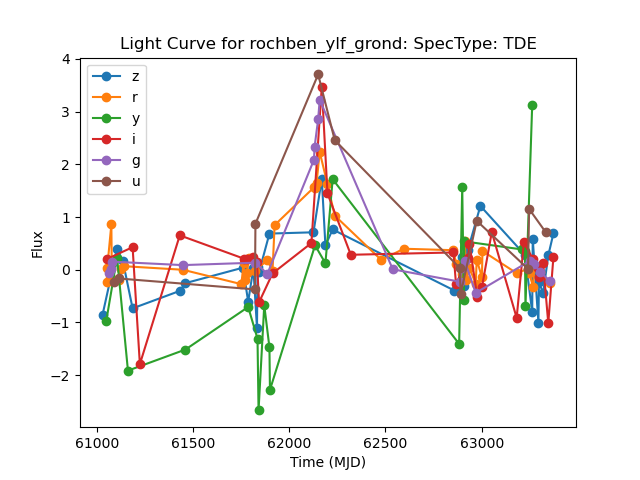

Oggetto: romru_hud_tobas (SpecType: TDE)


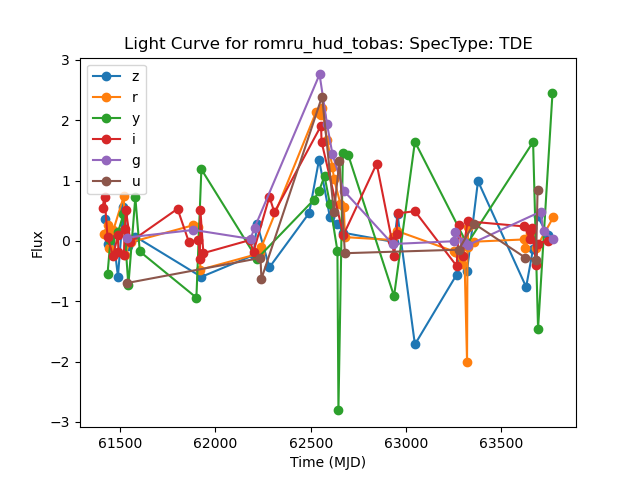

Oggetto: gwaloth_fuin_pendrath (SpecType: TDE)


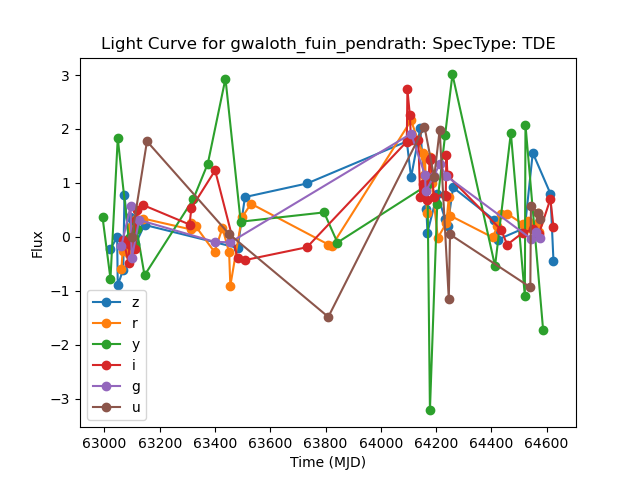

Oggetto: luith_puig_cabed (SpecType: TDE)


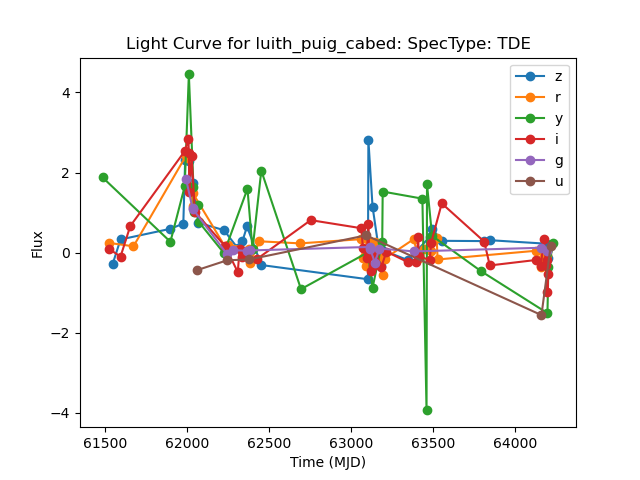

Oggetto: neledh_gwend_naer (SpecType: TDE)


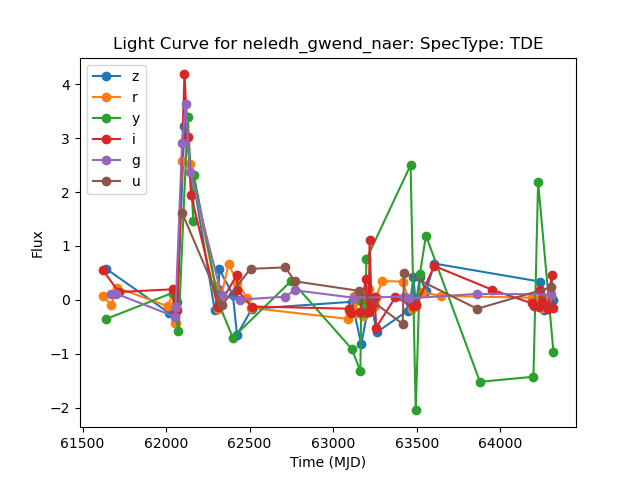

Oggetto: nimp_bragol_hwiniol (SpecType: TDE)


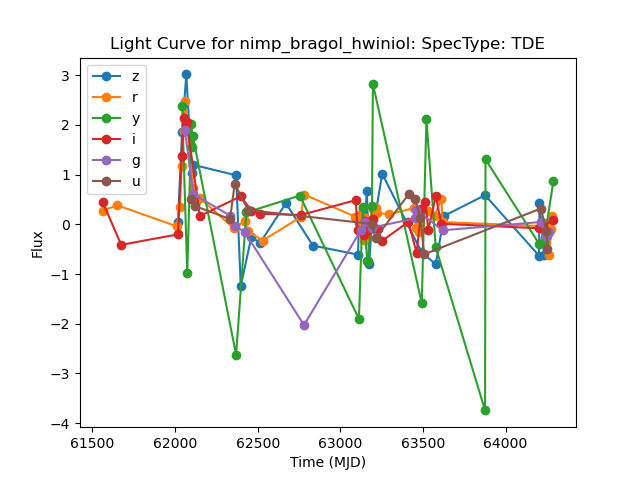

Oggetto: nost_loss_hal (SpecType: TDE)


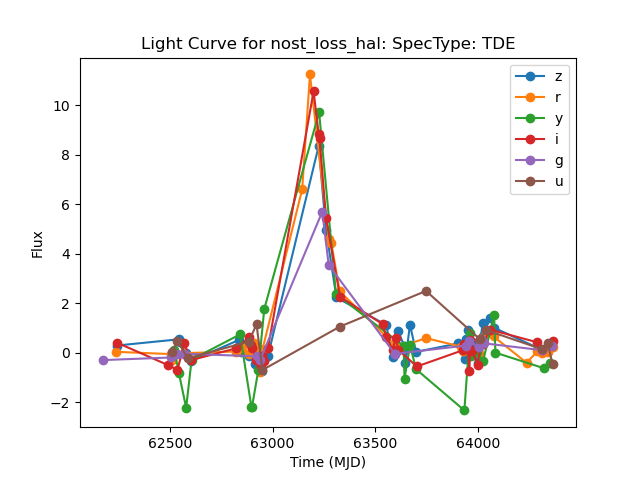

Oggetto: rochben_gwaloth_melethron (SpecType: TDE)


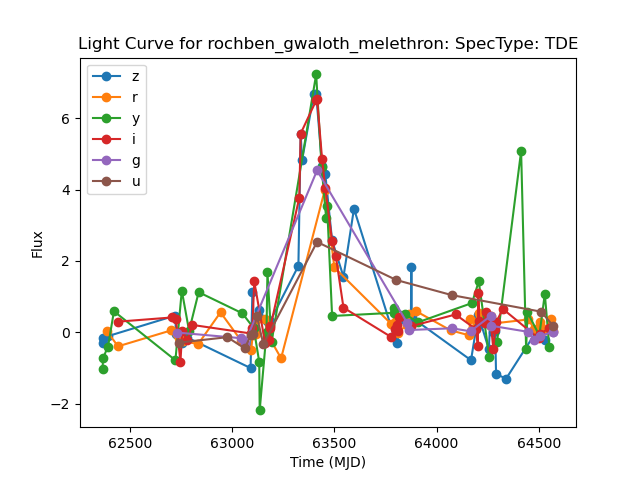

Oggetto: alph_alag_lunt (SpecType: TDE)


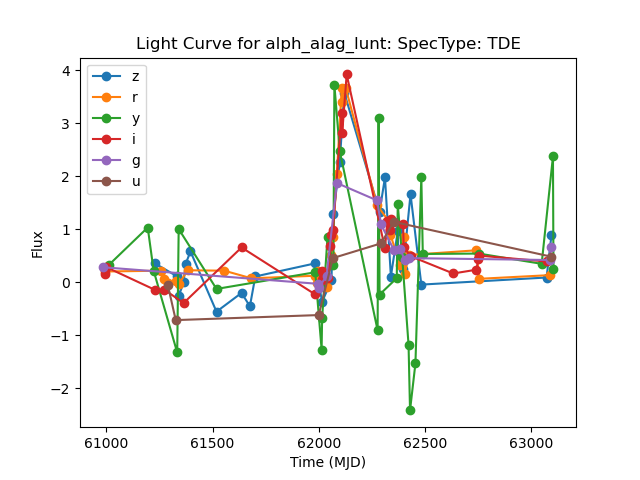

Oggetto: glamor_hul_firiel (SpecType: TDE)


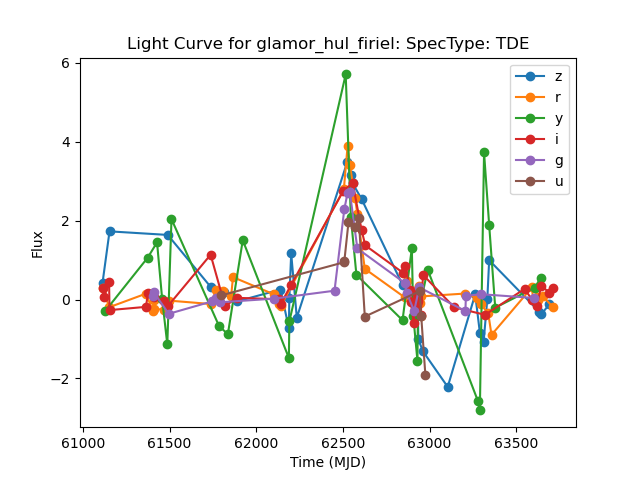

Oggetto: glass_cirion_agar (SpecType: TDE)


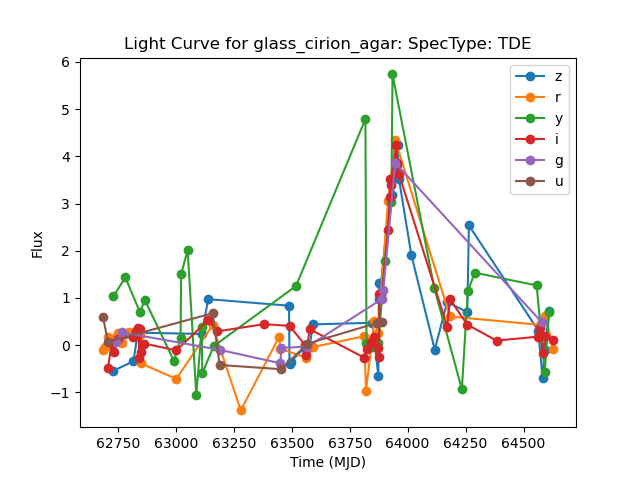

Oggetto: hub_grond_barad (SpecType: TDE)


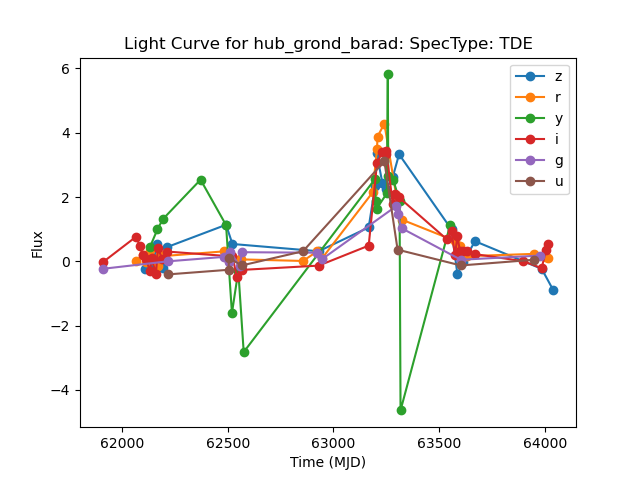

Oggetto: maecheneb_cund_lavan (SpecType: TDE)


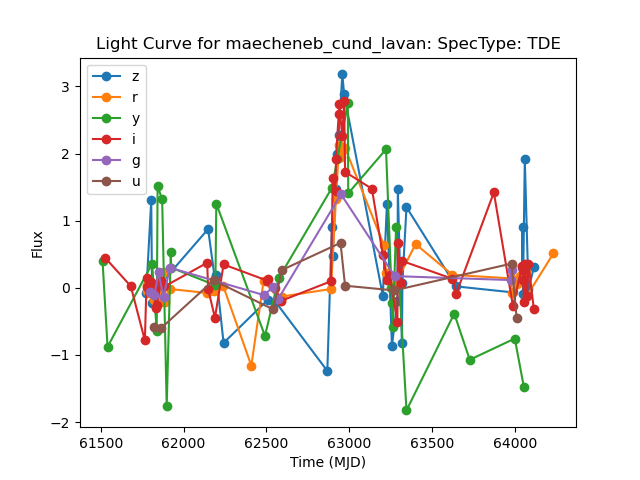

Oggetto: rust_raug_eglan (SpecType: TDE)


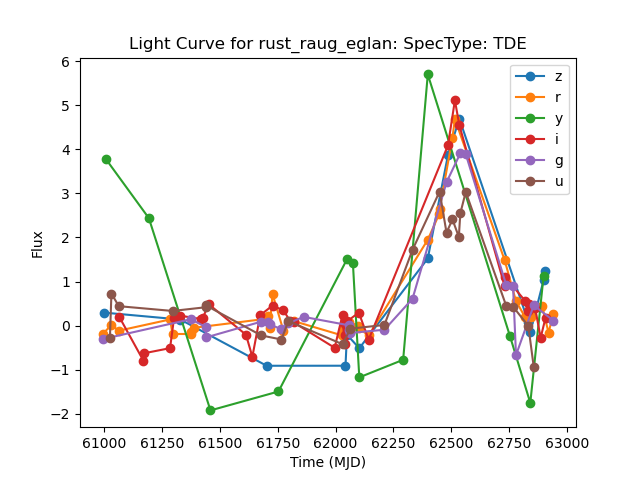

Oggetto: saig_minuial_ungol (SpecType: TDE)


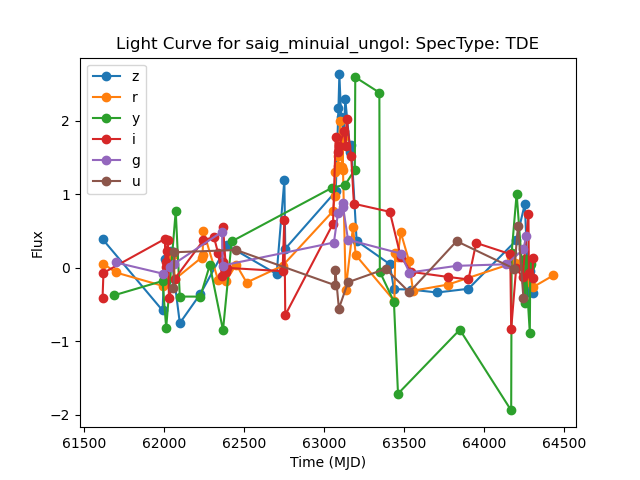

Oggetto: talraph_myril_aras (SpecType: TDE)


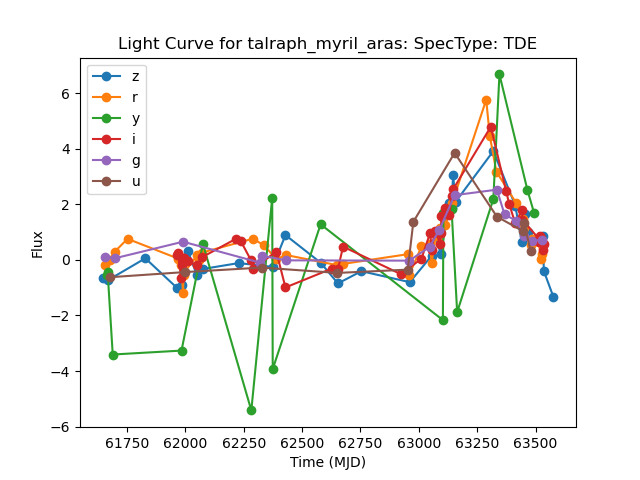

Oggetto: vin_aranarth_dol (SpecType: TDE)


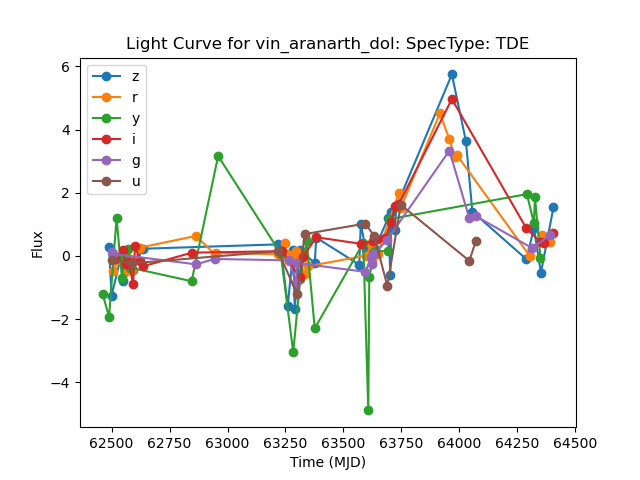

Oggetto: Ennor_imloth_morgul (SpecType: TDE)


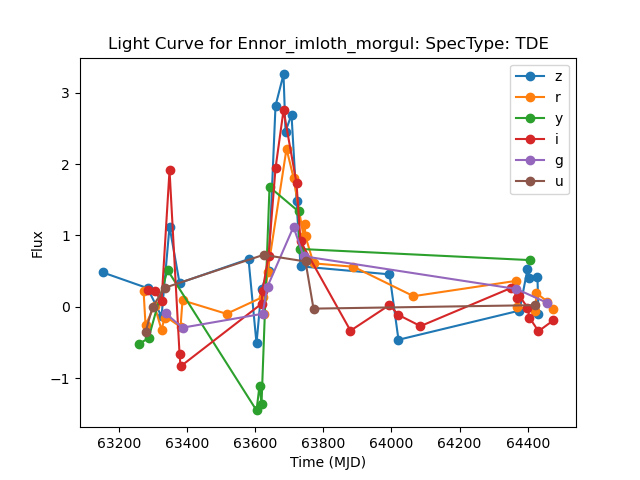

Oggetto: Gonhir_fast_romru (SpecType: TDE)


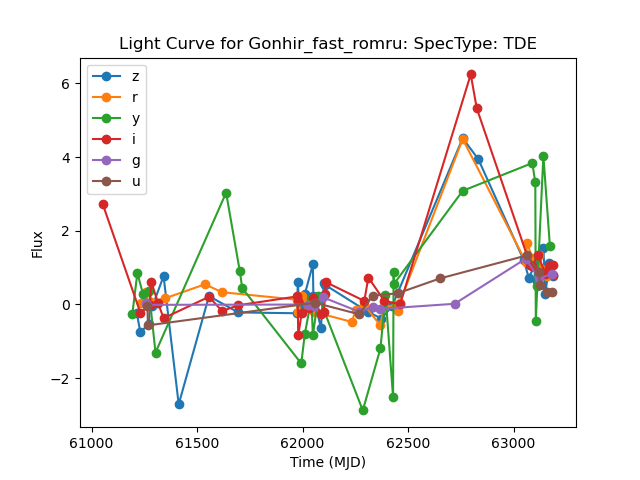

Oggetto: ablad_vin_faen (SpecType: TDE)


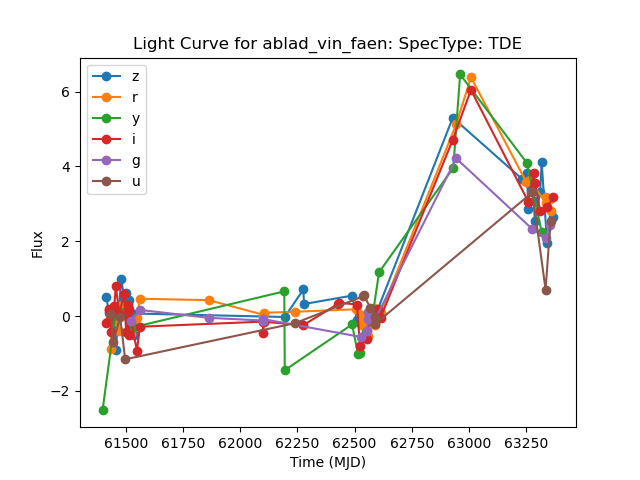

Oggetto: adel_pethron_imrad (SpecType: TDE)


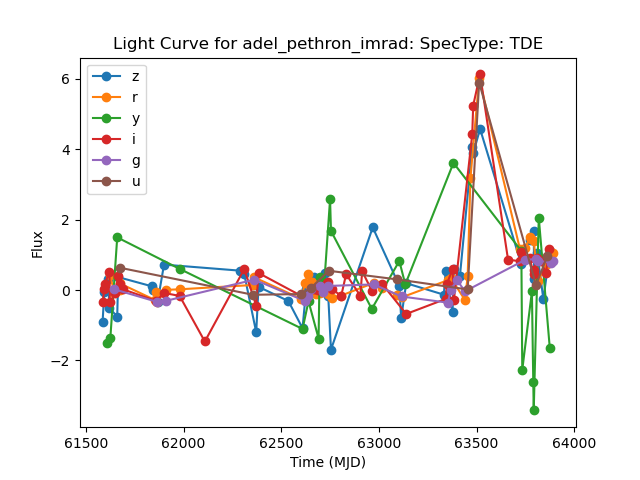

Oggetto: aeruil_corch_min (SpecType: TDE)


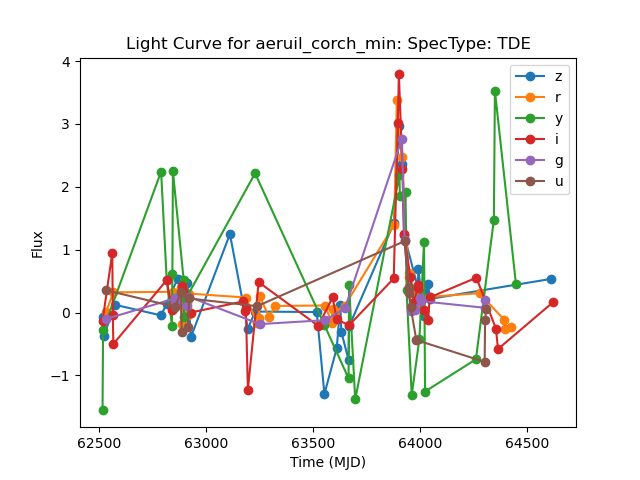

Oggetto: celair_ang_uan (SpecType: TDE)


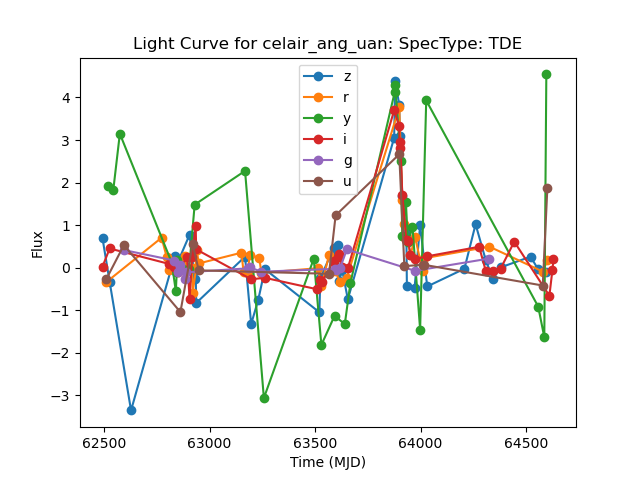

Oggetto: lachenn_badhor_gwend (SpecType: TDE)


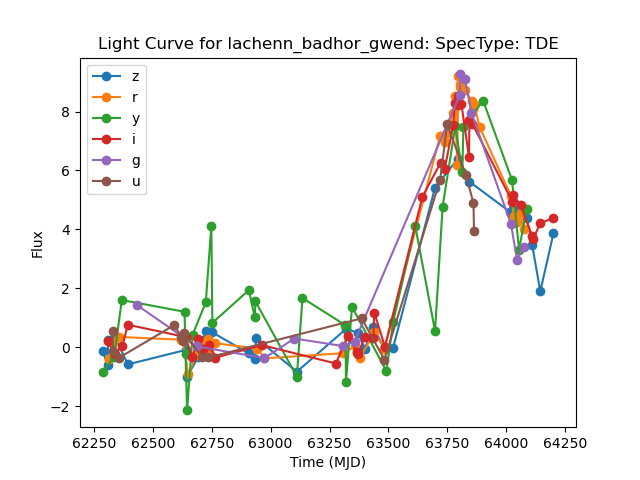

Oggetto: lam_maecheneb_limlug (SpecType: TDE)


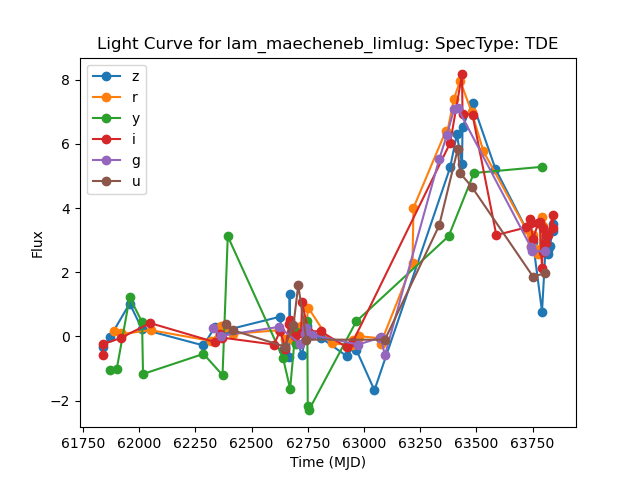

Oggetto: lebdas_ryn_hend (SpecType: TDE)


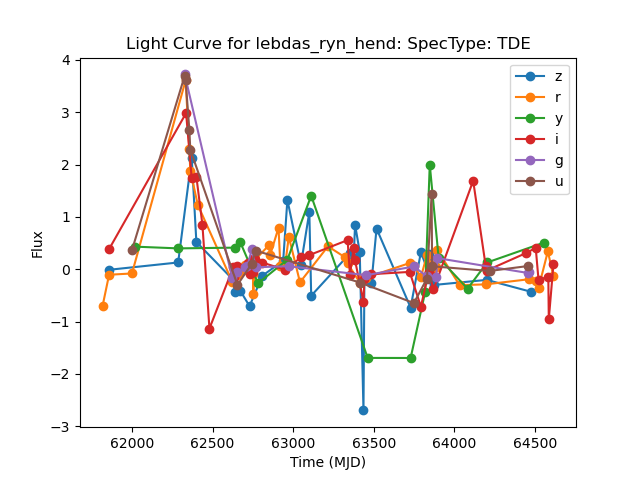

Oggetto: midh_morn_eglan (SpecType: TDE)


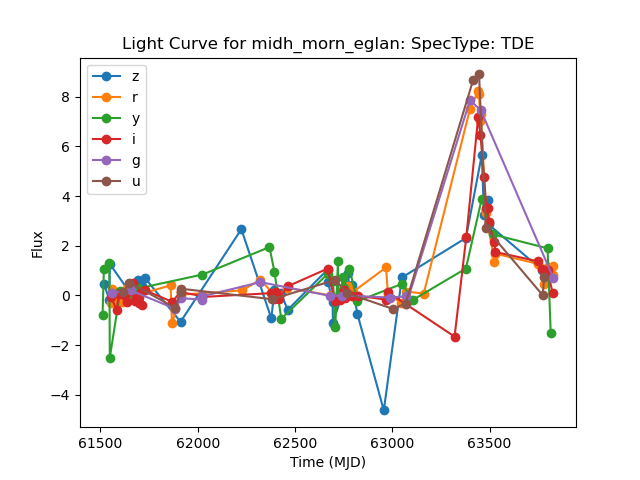

Oggetto: midh_pennas_neledh (SpecType: TDE)


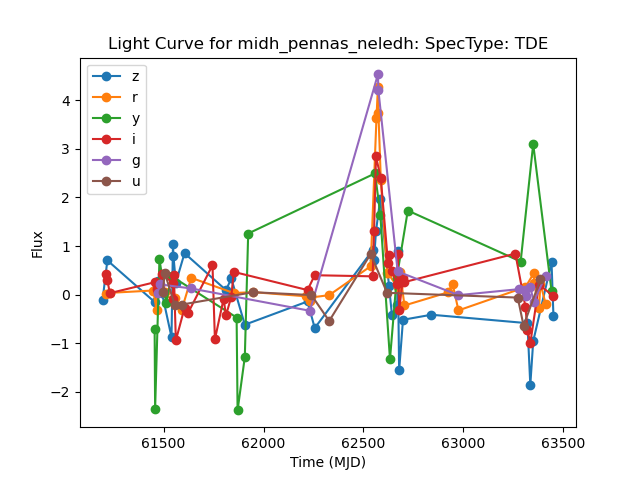

Oggetto: soga_Eru_muil (SpecType: TDE)


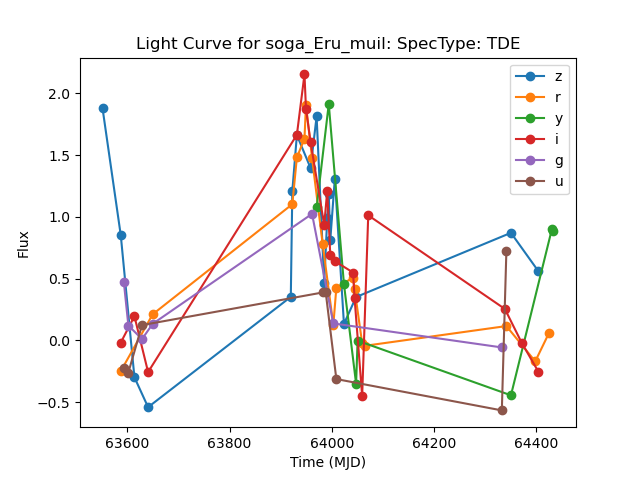

Oggetto: ai_peredhel_laer (SpecType: TDE)


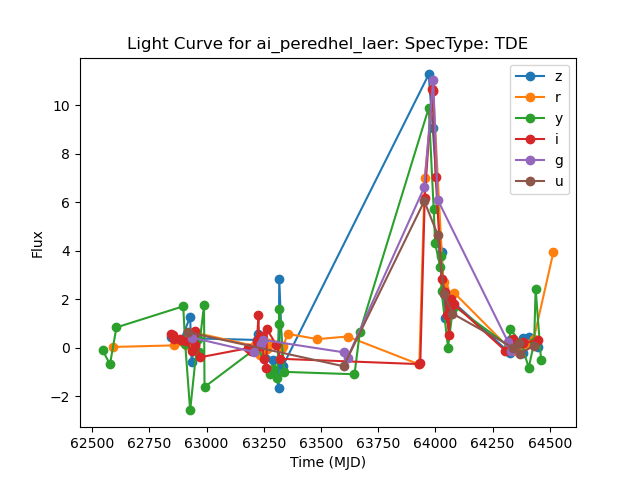

Oggetto: bass_archam_rhosc (SpecType: TDE)


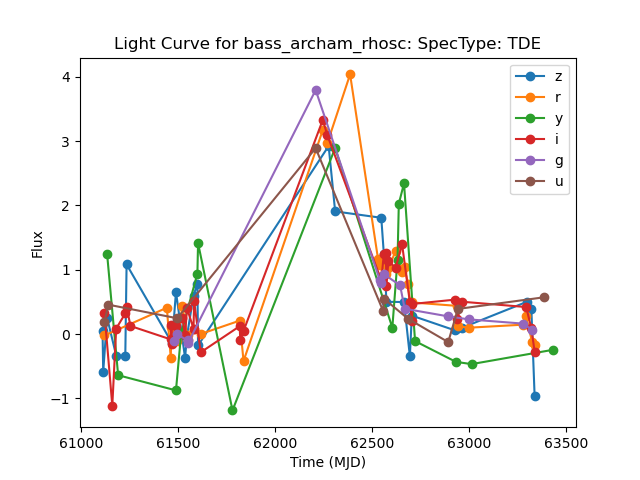

Oggetto: cirion_ungol_ira (SpecType: TDE)


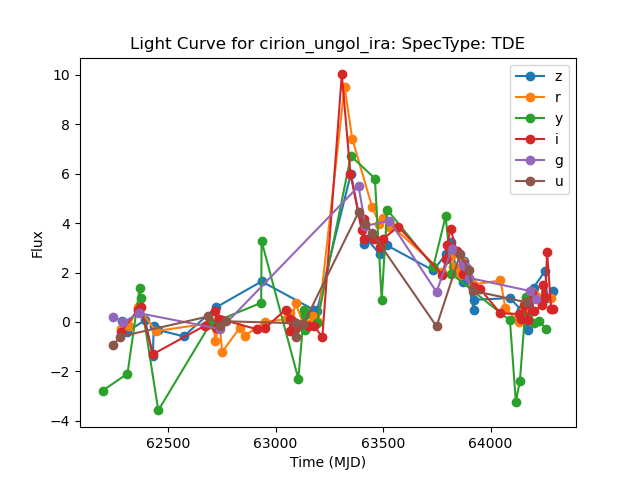

Oggetto: cuil_noroth_tachol (SpecType: TDE)


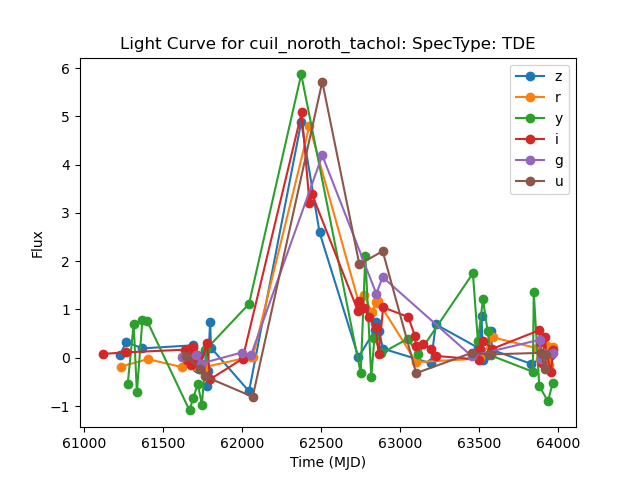

Oggetto: daen_loss_Druadan (SpecType: TDE)


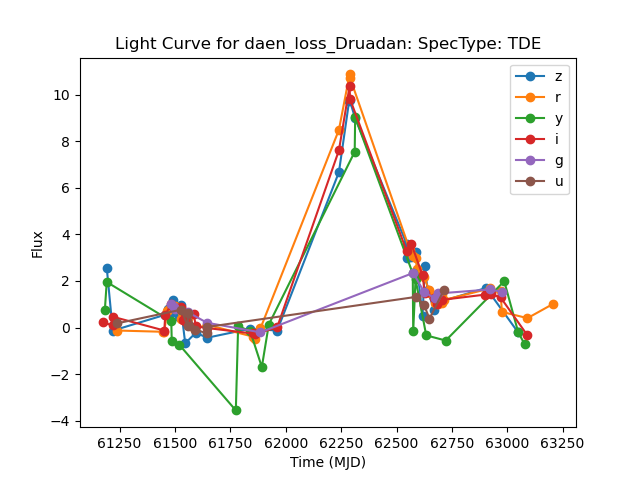

Oggetto: dunedhel_saer_lorn (SpecType: TDE)


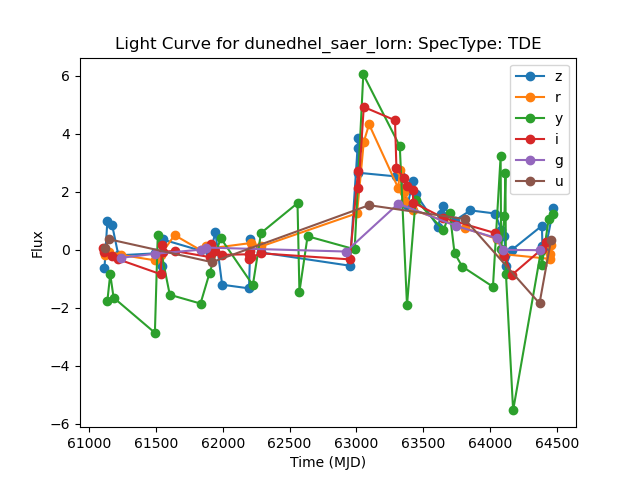

Oggetto: gobennas_nath_rochben (SpecType: TDE)


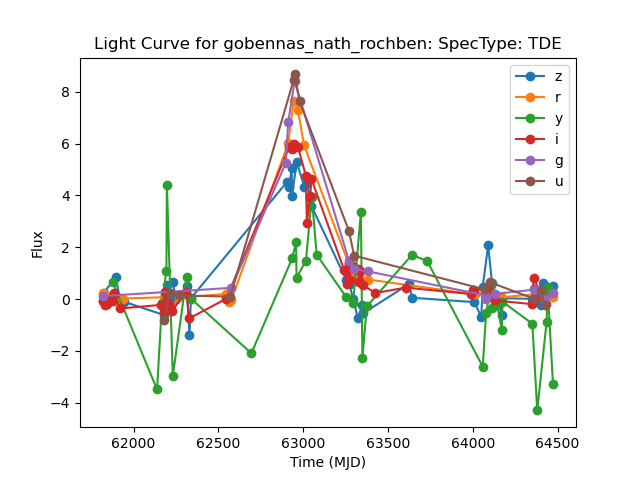

Oggetto: gul_glamog_gaur (SpecType: TDE)


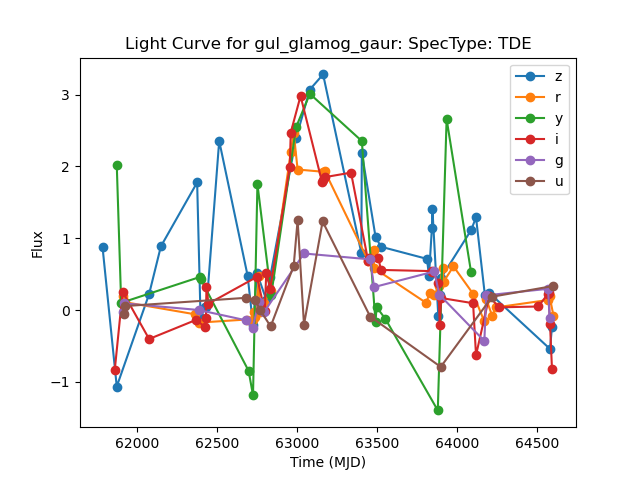

Oggetto: hun_pilin_mindon (SpecType: TDE)


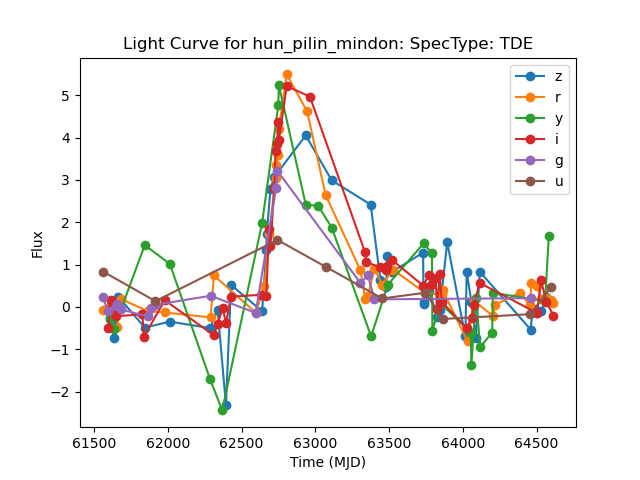

Oggetto: imloth_firiel_certh (SpecType: TDE)


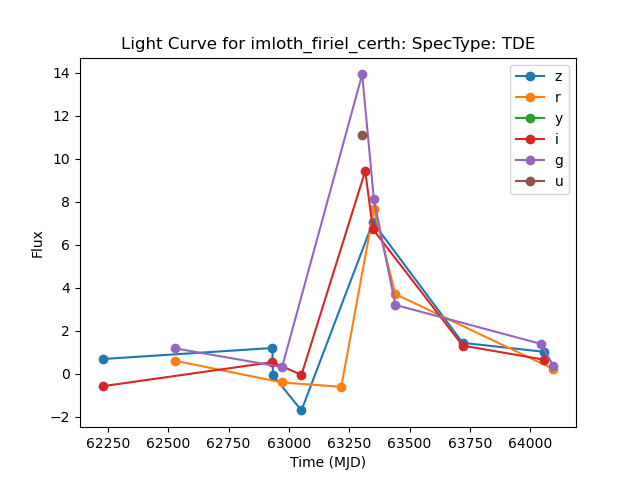

Oggetto: imrad_in_puig (SpecType: TDE)


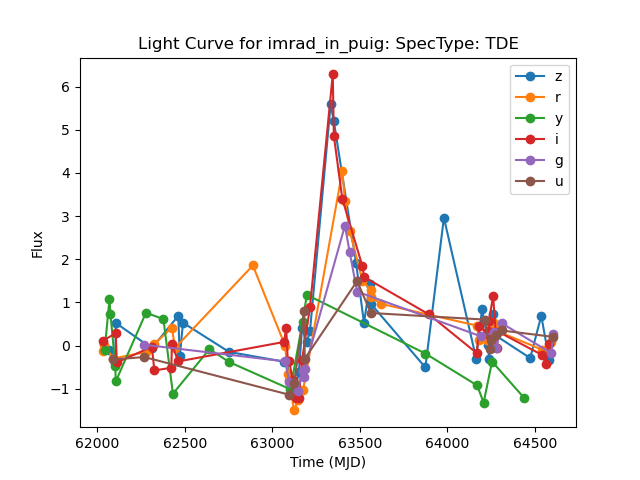

Oggetto: lunt_sogannen_certh (SpecType: TDE)


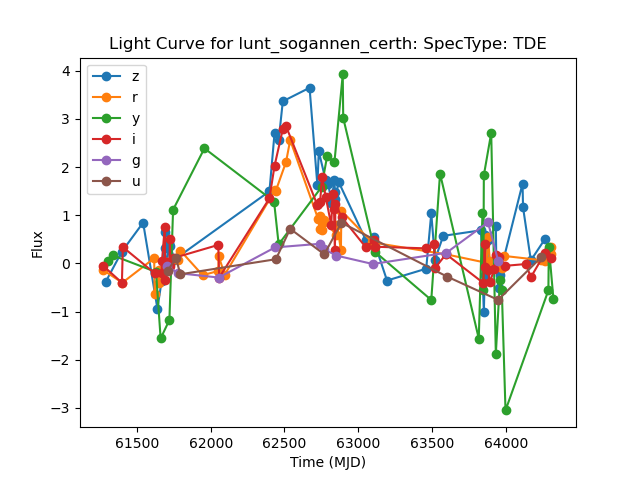

Oggetto: min_talraph_Sindarin (SpecType: TDE)


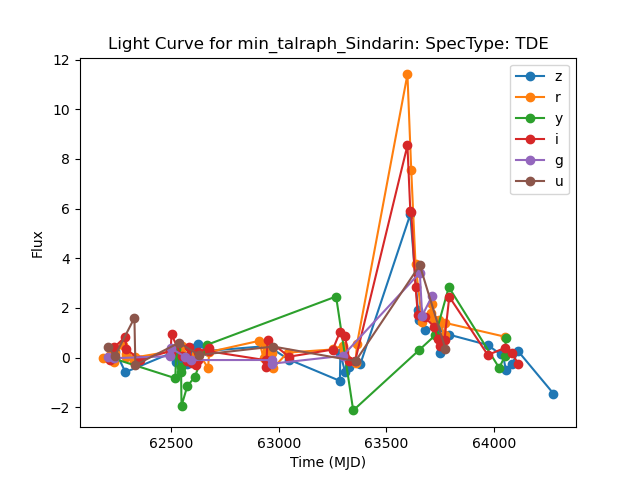

Oggetto: pennas_sammar_Dornhoth (SpecType: TDE)


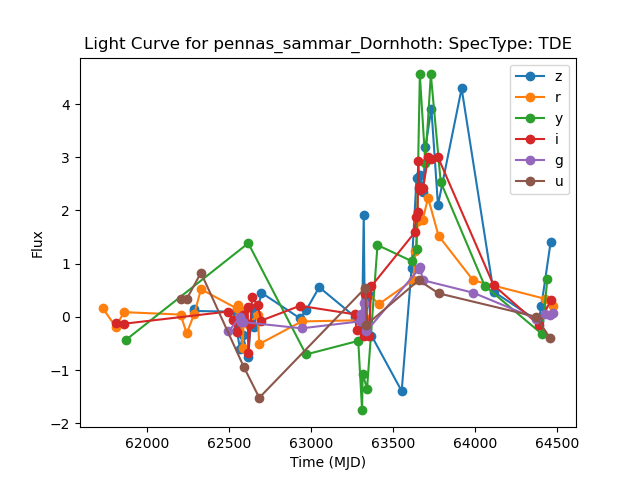

Oggetto: tamin_aduial_parf (SpecType: TDE)


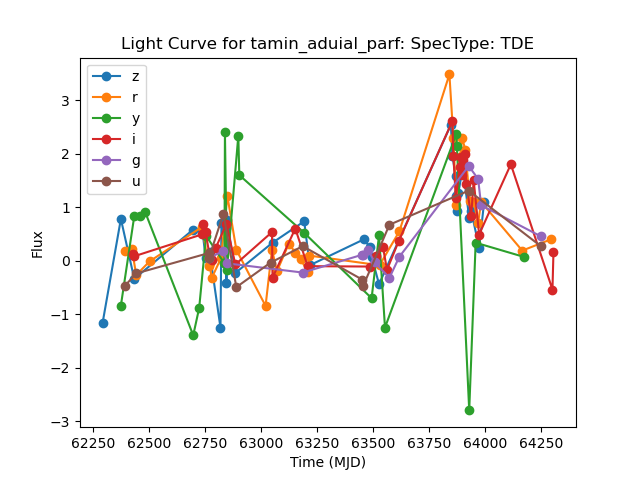

Oggetto: aerlinn_heron_luith (SpecType: TDE)


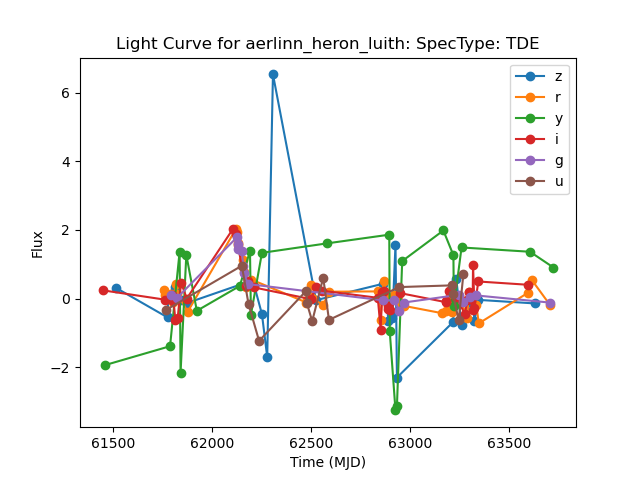

Oggetto: alae_dol_nimp (SpecType: TDE)


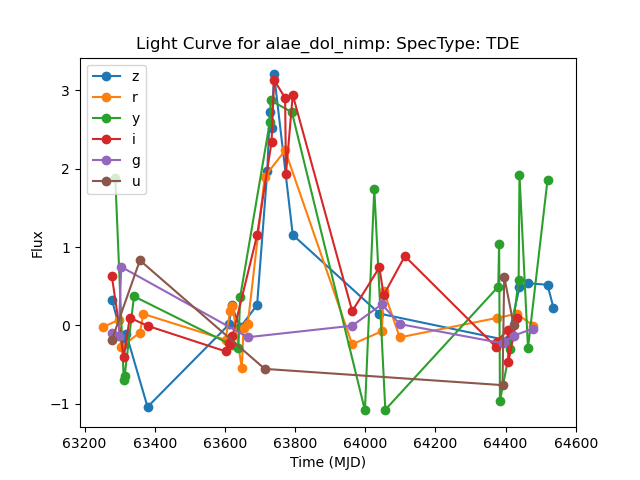

Oggetto: cabor_gaurwaith_Gwathuirim (SpecType: TDE)


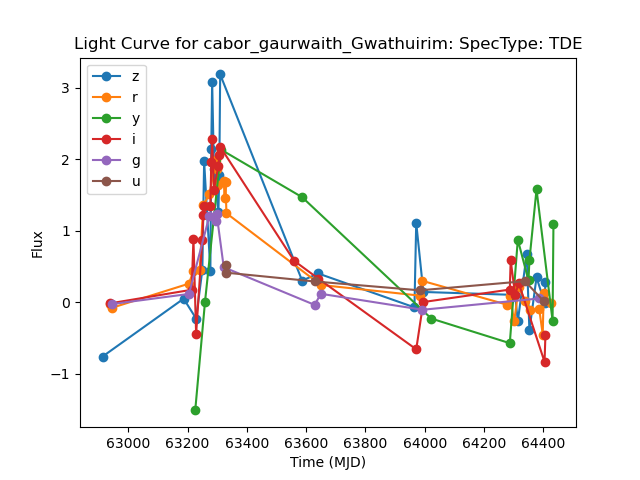

Oggetto: fang_saelor_gellui (SpecType: TDE)


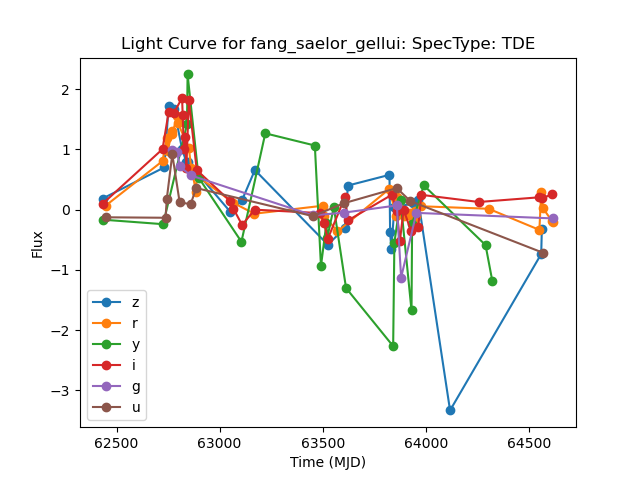

Oggetto: neledh_tinuviel_inias (SpecType: TDE)


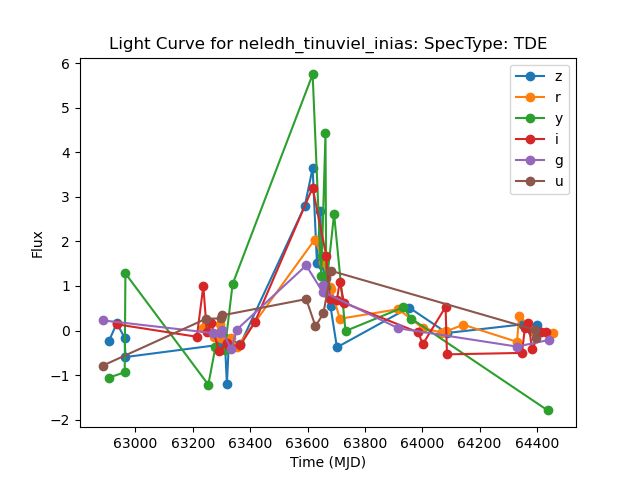

Oggetto: talraph_gwael_lunt (SpecType: TDE)


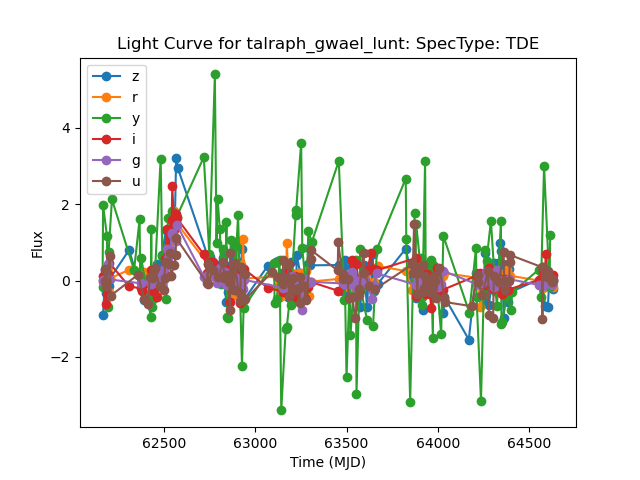

Oggetto: adab_thul_rust (SpecType: TDE)


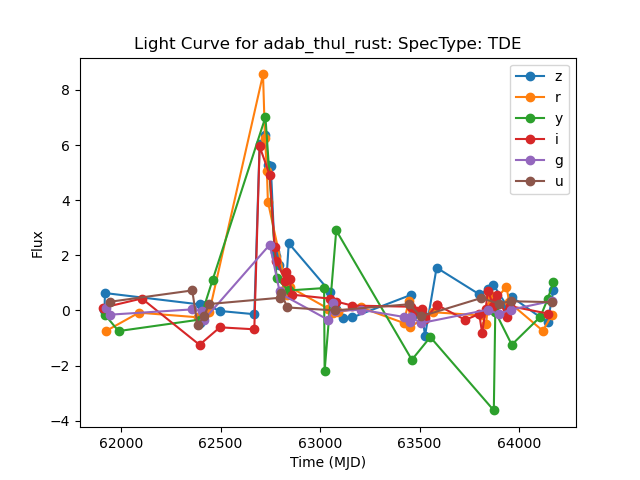

Oggetto: eilian_perian_glamor (SpecType: TDE)


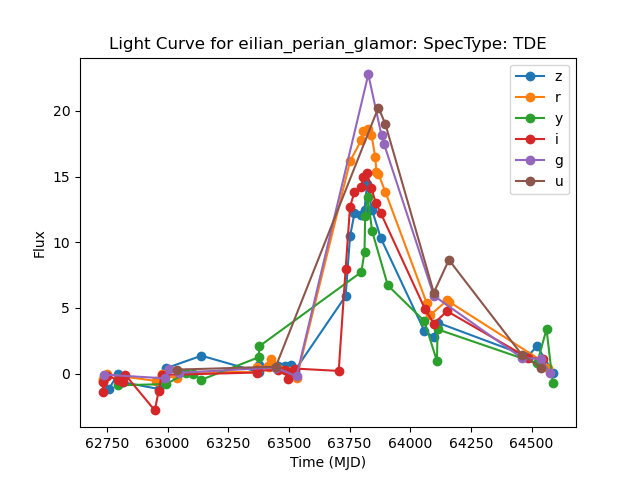

Oggetto: galvorn_suil_fang (SpecType: TDE)


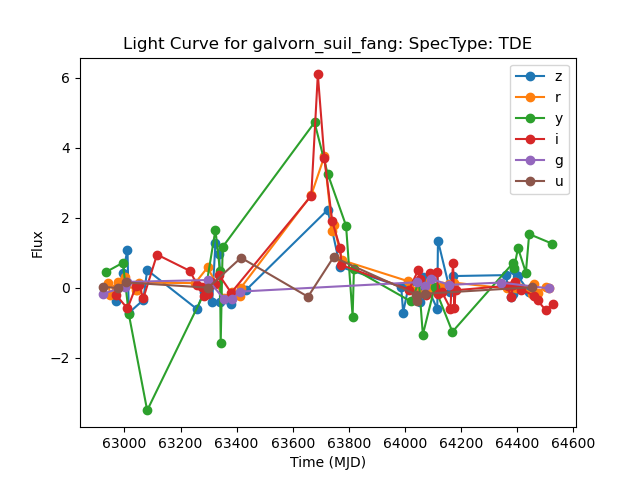

Oggetto: heledir_idhren_melethril (SpecType: TDE)


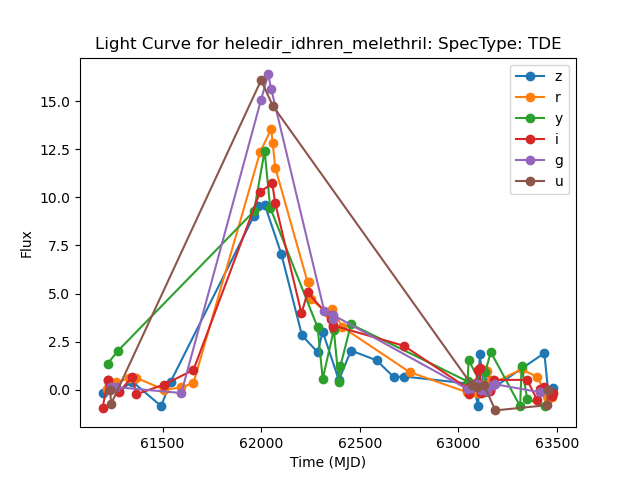

Oggetto: lathron_pess_aith (SpecType: TDE)


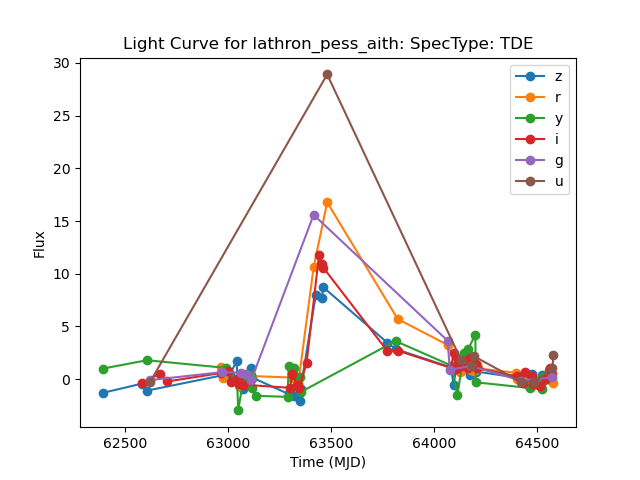

Oggetto: lembas_uan_laug (SpecType: TDE)


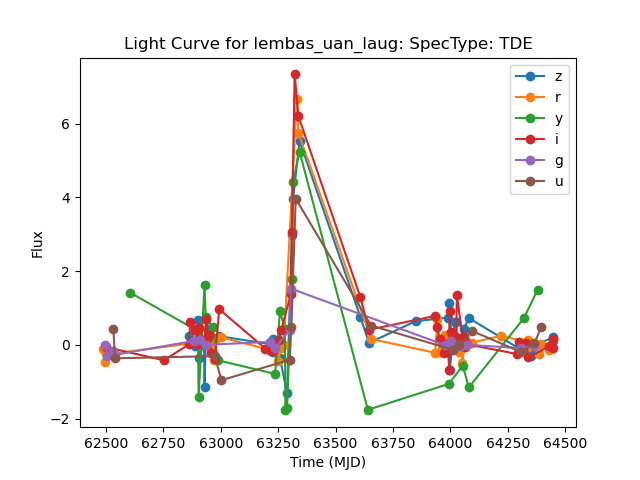

Oggetto: acharn_per_gwaloth (SpecType: TDE)


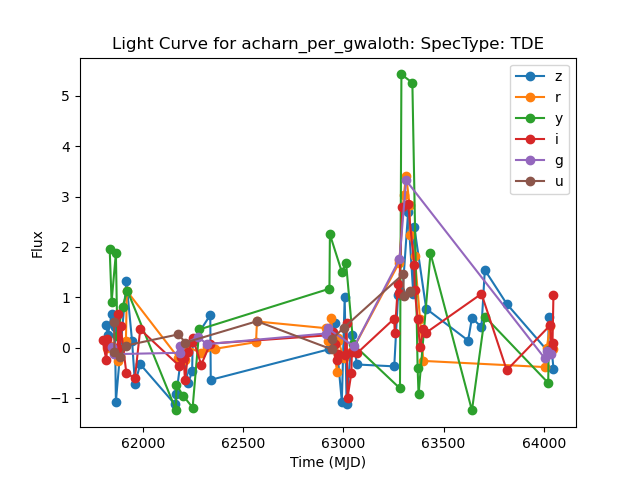

Oggetto: ah_achad_bain (SpecType: TDE)


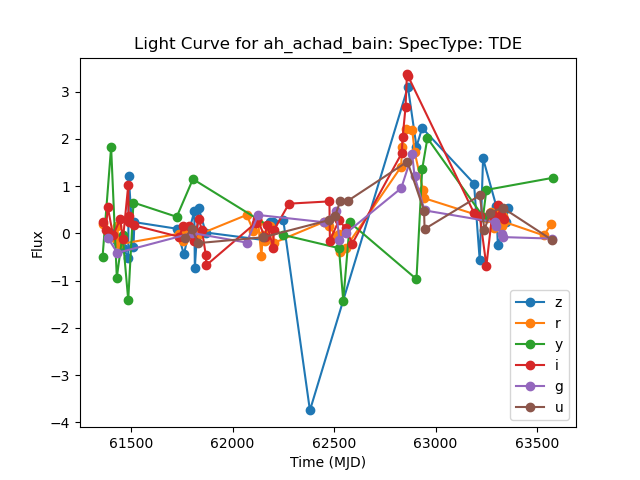

Oggetto: amon_corch_idhren (SpecType: TDE)


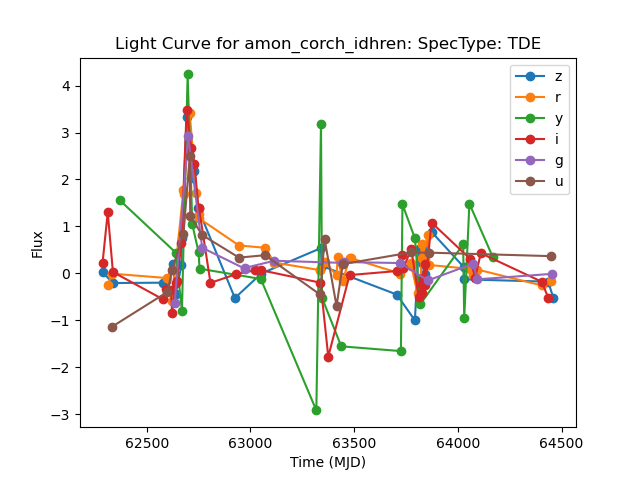

Oggetto: araf_glamog_echad (SpecType: TDE)


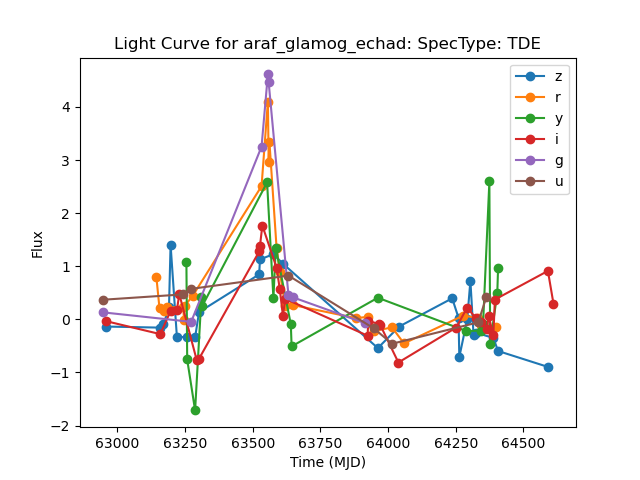

Oggetto: badhor_talraph_lam (SpecType: TDE)


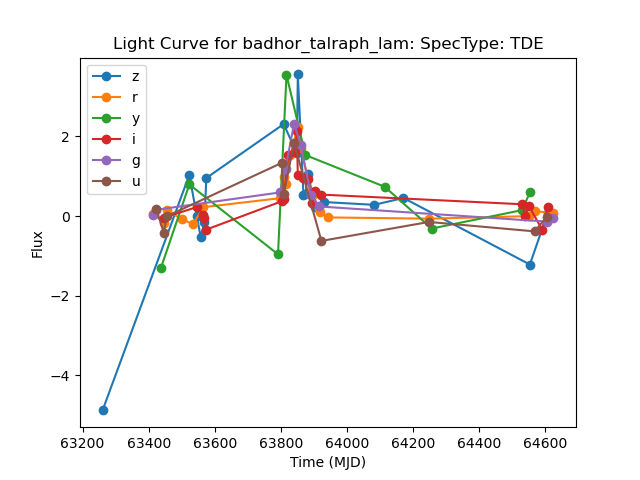

Oggetto: cabed_mereth_iphant (SpecType: TDE)


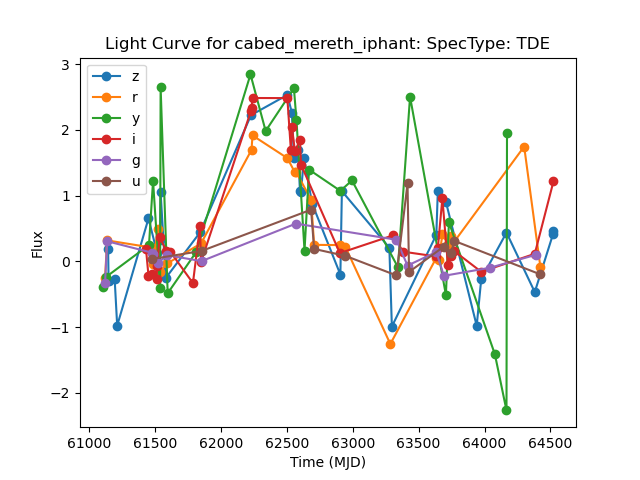

Oggetto: dirnaith_aphadrim_adab (SpecType: TDE)


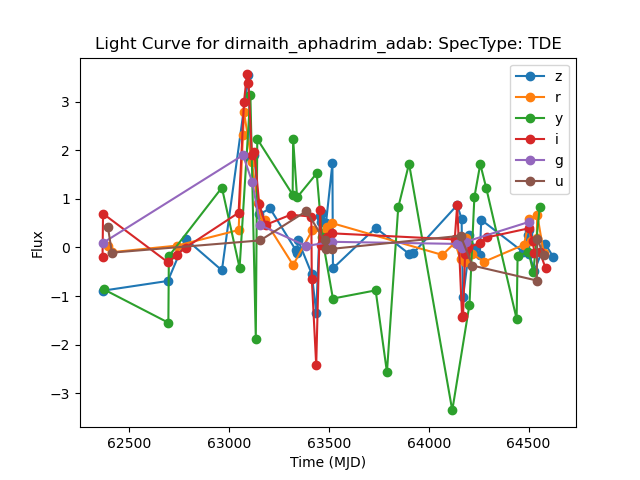

Oggetto: glamor_iar_amloth (SpecType: TDE)


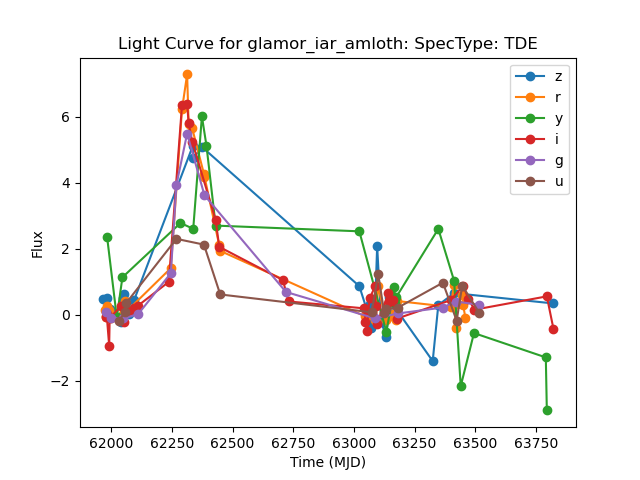

Oggetto: lacha_eirien_fang (SpecType: TDE)


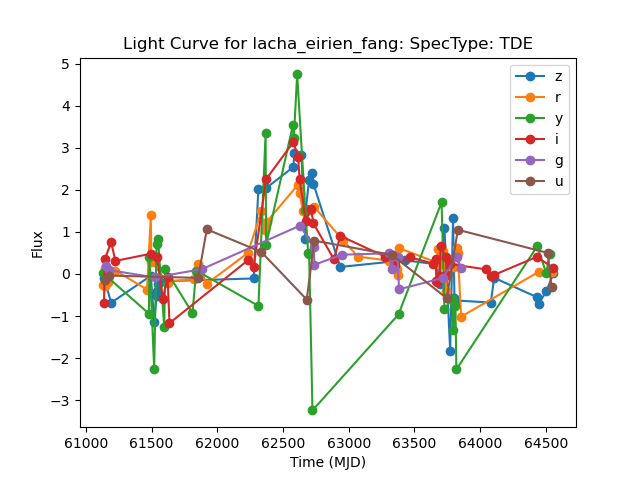

Oggetto: mund_callon_merilin (SpecType: TDE)


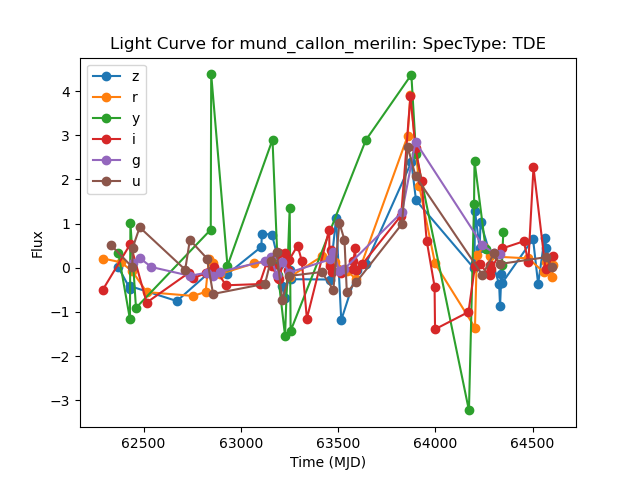

Oggetto: mund_galas_rust (SpecType: TDE)


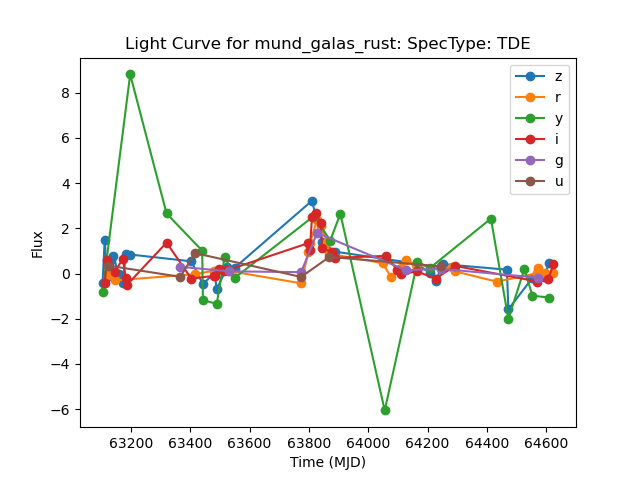

Oggetto: nadhras_ylf_in (SpecType: TDE)


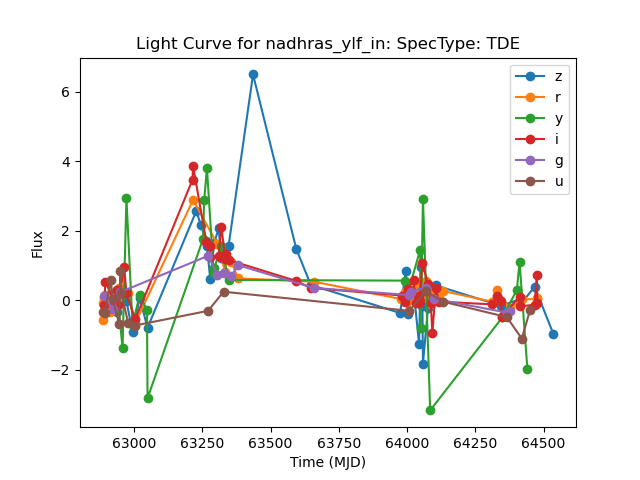

Oggetto: rhach_lorn_Tawarwaith (SpecType: TDE)


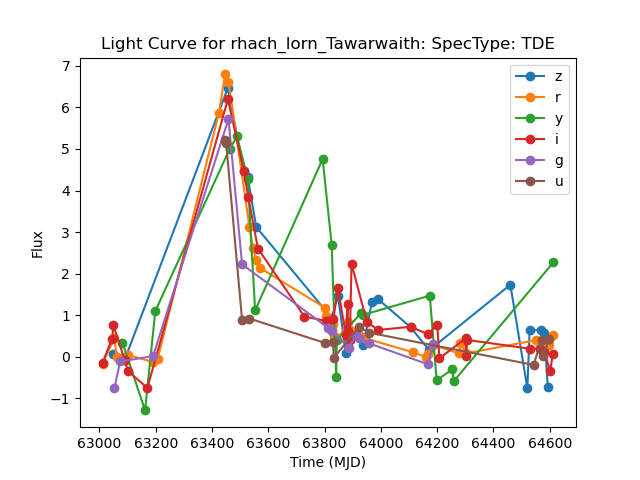

Oggetto: yll_merilin_rach (SpecType: TDE)


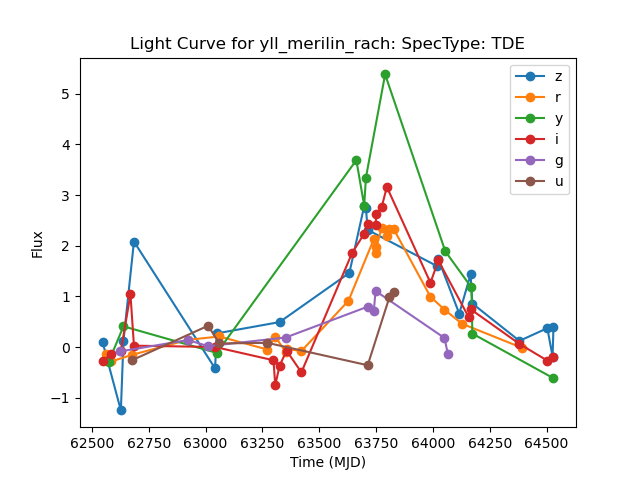

Oggetto: anann_ungol_agarwaen (SpecType: TDE)


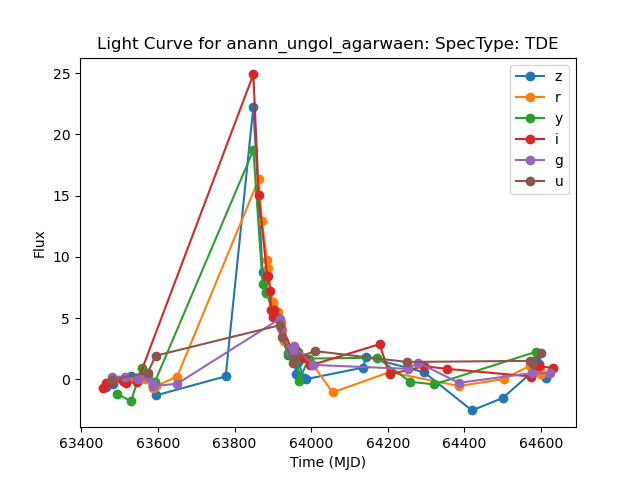

Oggetto: bragol_laes_tathar (SpecType: TDE)


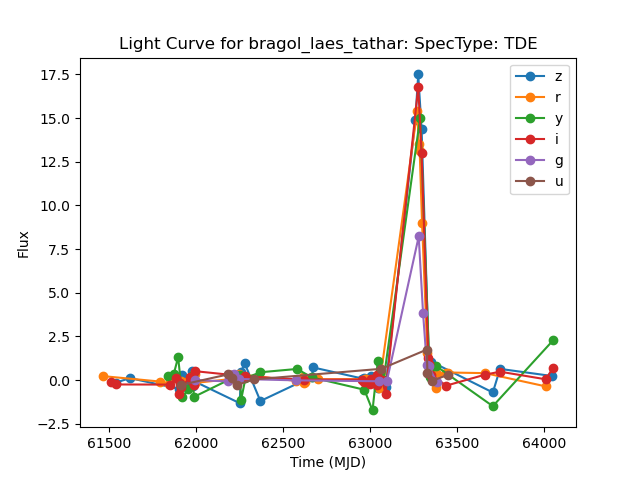

Oggetto: braig_loss_hal (SpecType: TDE)


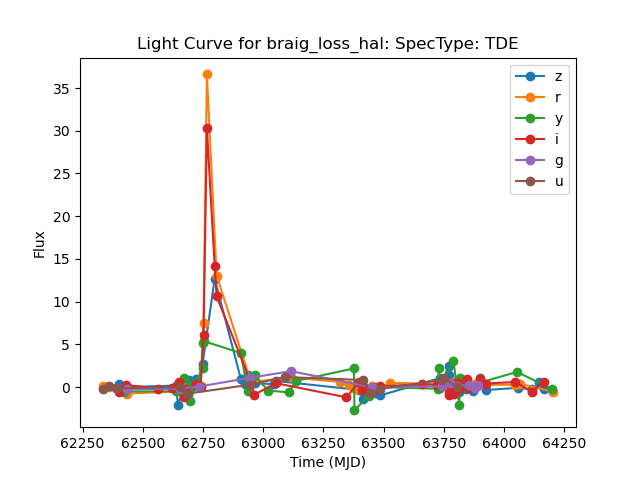

Oggetto: dannas_glandagol_maethor (SpecType: TDE)


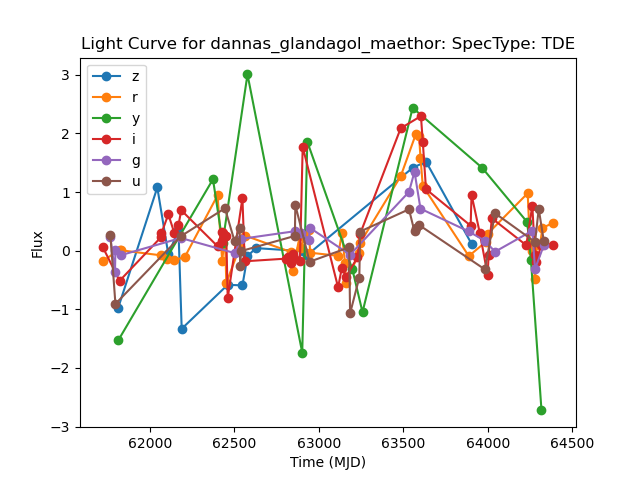

Oggetto: hul_firion_callon (SpecType: TDE)


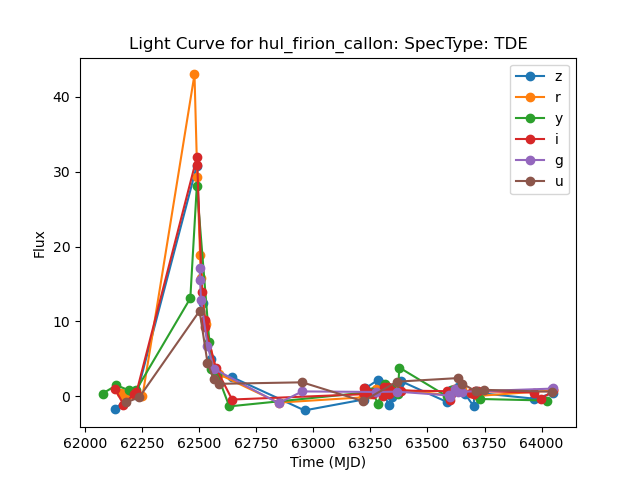

Oggetto: lin_graw_hend (SpecType: TDE)


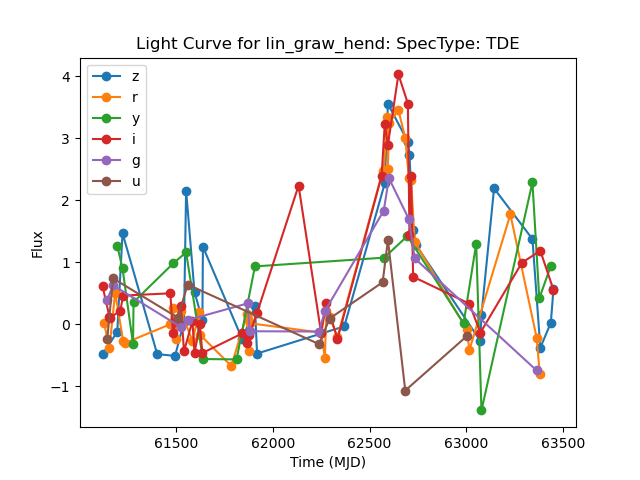

Oggetto: myril_uir_lost (SpecType: TDE)


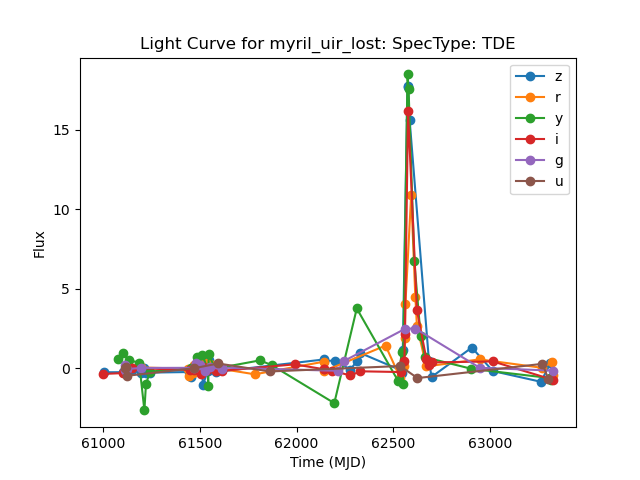

Oggetto: nath_lang_naer (SpecType: TDE)


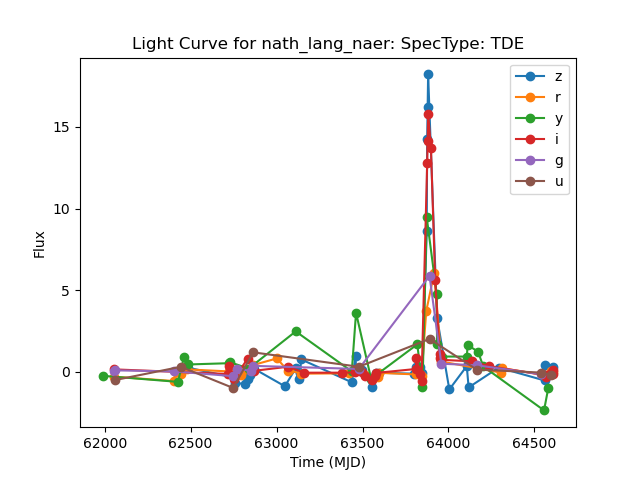

Oggetto: rach_lass_tathar (SpecType: TDE)


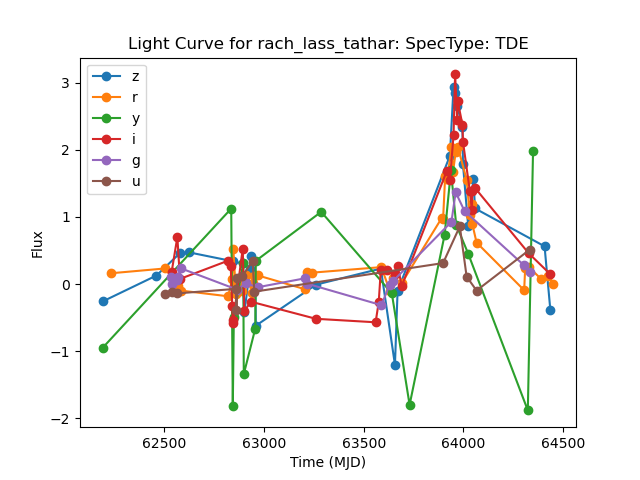

In [34]:
import os
from IPython.display import Image, display

# 1. Ottieni la lista di object_id che sono TDE dal log
tde_list = train_log[train_log['SpecType'] == 'TDE']['object_id'].unique()

folder = 'curves_plot'
print(f"Visualizzazione dei grafici TDE trovati in '{folder}':\n")

count = 0
for object_id in tde_list:
    # Costruiamo il nome del file basandoci su come lo hai salvato prima
    file_path = f"{folder}/{object_id}_lightcurve.png"
    
    # Controlliamo se il file esiste effettivamente nella cartella
    if os.path.exists(file_path):
        print(f"Oggetto: {object_id} (SpecType: TDE)")
        display(Image(filename=file_path))
        count += 1

if count == 0:
    print("Nessun grafico TDE trovato. Controlla i nomi dei file o lo SpecType.")

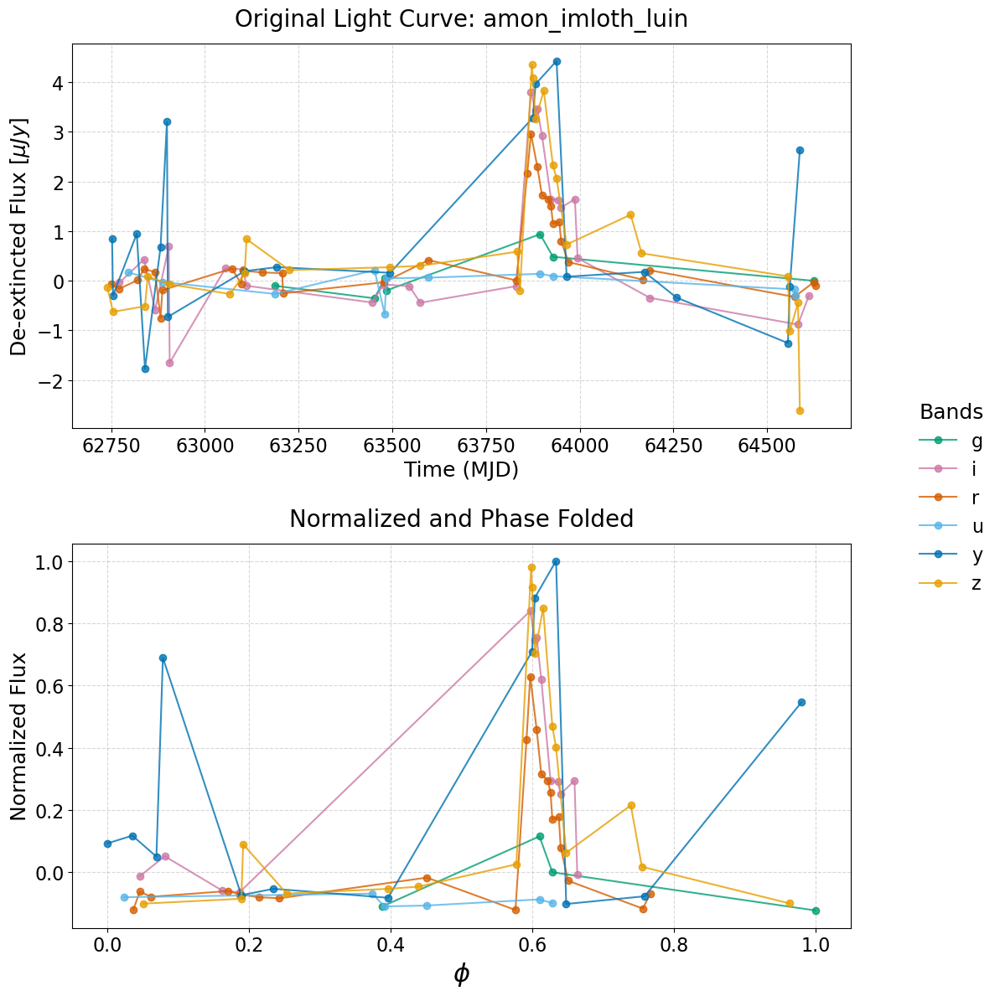

In [35]:

band_colors = {
    'u': '#56B4E9', 'g': '#009E73', 'r': '#D55E00', 
    'i': '#CC79A7', 'z': '#E69F00', 'y': '#0072B2',
}

obj_id = 'amon_imloth_luin'

# Create the figure with 2 rows and 1 column
# Increased height (12) to accommodate vertical stacking
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

# --- Plot 1: Original Data ---
data_orig = df_train[df_train['object_id'] == obj_id]
bands_orig = sorted(data_orig['Filter'].unique())

for band in bands_orig:
    subset = data_orig[data_orig['Filter'] == band].sort_values(by='Time (MJD)')
    ax1.plot(subset['Time (MJD)'], subset['Flux_ext'], 
             marker='o', markersize=6, color=band_colors.get(band, 'black'), alpha=0.8)

ax1.set_ylabel(r'De-extincted Flux [$\mu Jy$]', fontsize=18)
ax1.set_xlabel('Time (MJD)', fontsize=18)
ax1.tick_params(axis='both', labelsize=16)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.set_title(f'Original Light Curve: {obj_id}', fontsize=20, pad=15)

# --- Plot 2: Noise Removed ---
data_clean = df_train_noise_removed[df_train_noise_removed['object_id'] == obj_id]
bands_clean = sorted(data_clean['Filter'].unique())

for band in bands_clean:
    subset = data_clean[data_clean['Filter'] == band].sort_values(by='phi')
    # Label added here for the common legend
    ax2.plot(subset['phi'], subset['F_norm'], 
             label=band, marker='o', markersize=6, color=band_colors.get(band, 'black'), alpha=0.8)

ax2.set_ylabel('Normalized Flux', fontsize=18)
ax2.set_xlabel(r'$\phi$', fontsize=22)
ax2.tick_params(axis='both', labelsize=16)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_title('Normalized and Phase Folded', fontsize=20, pad=15)

# --- Create a Common Legend ---
handles, labels = ax2.get_legend_handles_labels()

# Placing the legend to the right of the plots
fig.legend(handles, labels, loc='center right', fontsize=16, 
           title="Bands", title_fontsize=18, frameon=False)

plt.tight_layout()
# Adjusting right margin to make room for the legend
plt.subplots_adjust(right=0.85, hspace=0.3) 
plt.show()

Saving curves

In [36]:
save_stacked_curves(df_train_filtered,'stacked_curves_short', -150, 200)# filtered training short


save_stacked_curves(df_train_noise_removed,'stacked_curves_short_all_train', -150, 200) #all lc short train
save_stacked_curves(df_val_noise_removed,'stacked_curves_short_all_val', -150, 200) #all lc short val

Saved 672 files with fixed physical timing.
Saved 2417 files with fixed physical timing.
Saved 603 files with fixed physical timing.


Test dataset

In [37]:
df_test_final = df_test.sort_values('Time (MJD)') #Sorting by time
df_test_final = df_test_final[df_test_final['Flux_ext'] >= 0.0] #Removing negative fluxes


In [38]:
# --- FOR TEST SET ---
features_per_band_test = df_test_final.groupby(['object_id', 'Filter']).apply(get_features)
df_features_test = features_per_band_test.unstack(level='Filter').stack(level=0).unstack(level=1)
df_features_test.columns = [f"{col[1]}_{col[0]}" if isinstance(col, tuple) else col for col in df_features_test.columns]
df_features_test = df_features_test.reset_index().fillna(-9999)






In [39]:
df_features_test.to_csv('df_features_test.csv', index=True)

Computing t_0 for the test dataset

In [40]:
t0_per_object = (
    df_test_final.groupby('object_id').apply(
        lambda obj: obj.loc[obj['Flux'].idxmax(), 'Time (MJD)']
        if obj['Flux_ext'].notna().any() else obj['Time (MJD)'].median()
    )
)

# Map t0 back to df_test_final
df_test_final['t0'] = df_test_final['object_id'].map(t0_per_object)

# Compute tau
df_test_final['tau'] = df_test_final['Time (MJD)'] - df_test_final['t0']

Removing noise

In [41]:
df_test_filtered = noise_removal(df_test_final) #FIltered test dataset


In [42]:
#Filtered test dataset
# Baseline, F_hat, Amplitude, F_norm, phi
F_base = df_test_filtered[df_test_filtered['tau']<0].groupby('object_id')['Flux_ext'].median()
df_test_filtered['F_base'] = df_test_filtered['object_id'].map(F_base)
df_test_filtered['F_hat'] = df_test_filtered['Flux_ext'] - df_test_filtered['F_base']
Amplitude = df_test_filtered.groupby('object_id')['F_hat'].max()
df_test_filtered['Amplitude'] = df_test_filtered['object_id'].map(Amplitude)
df_test_filtered = df_test_filtered[df_test_filtered['Amplitude']>0]
df_test_filtered['F_norm'] = df_test_filtered['F_hat']/df_test_filtered['Amplitude']
df_test_filtered['phi'] = df_test_filtered.groupby('object_id')['tau'].transform(
    lambda x: (x-x.min())/(x.max()-x.min()) if x.max()!=x.min() else 0.0
)
df_test_filtered['F_norm_err'] = df_test_filtered['Flux_err'] / df_test_filtered['Amplitude']

Saving stacked curves

In [43]:
save_stacked_curves(df_test_filtered,'stacked_curves_short_test', -150, 200)# filtered test short

Saved 7087 files with fixed physical timing.
